# Simulación y Optimización de Políticas de Inventarios

**UCASAL — Modelos y Simulación (Cohorte 2026) · Modalidad A**  
**Autor:** Leandro Joaquín Tabarcache

Este cuaderno ejecuta de extremo a extremo el simulador discreto paso a paso, las pruebas de verificación y validación, la búsqueda en grilla bajo Números Aleatorios Comunes (CRN), la comparación estadística de los cuatro escenarios sobre 100 réplicas y el análisis de sensibilidad.

In [2]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import copy
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import (
    DIR_IMG, DIR_RESULTADOS, ESCENARIOS, GRIDS,
    N_REPLICAS, N_REPLICAS_BUSQUEDA, N_REPLICAS_REFINAMIENTO, PARAMETROS,
)
from src.simulator import METRICAS, caminos_de_semilla, simular
from src.validation import chi2_lt, chi2_poisson, ejecutar_validacion_completa, validar_eoq
from src.experiments import (
    analisis_warmup, auditoria_estacionario, buscar_RS, buscar_sQ, correr_escenario,
    correlaciones_crn, ic95, preparar_caminos, pruebas_hipotesis, semillas,
    sensibilidad_K, sensibilidad_lt, sensibilidad_penalizacion,
)

p = PARAMETROS
print(f'SKU: {p.sku} | EOQ={p.eoq:.0f} u | Costo EOQ={p.costo_total_eoq():.2f} USD/año')
print(f's sin SS={p.s_sin_ss} u | sigma_D,LT={p.sigma_dl:.4f} u | s con SS (z=1.645)={p.s_con_ss} u')

SKU: RT-W6-100 | EOQ=200 u | Costo EOQ=1460.00 USD/año
s sin SS=28 u | sigma_D,LT=10.3923 u | s con SS (z=1.645)=45 u


## 1. Verificación estructural, ajuste de entrada y validación EOQ

Se ejecutan los invariantes diarios (conservación de flujo, no negatividad, identidad de posición), las pruebas $\chi^2$ para $D_t \sim \text{Poisson}(8)$ y $LT \sim U\{2,3,4,5\}$, y la convergencia exacta contra el modelo determinístico EOQ.

In [3]:
ok_vv = ejecutar_validacion_completa(guardar=False)
assert ok_vv, 'Falló un chequeo de verificación o validación'
display(pd.DataFrame([{'test': 'Poisson(8)', **chi2_poisson(p)}, {'test': 'U{2..5}', **chi2_lt(p)}]))
display(validar_eoq())

VERIFICACIÓN Y VALIDACIÓN DEL SIMULADOR DE INVENTARIOS

1. Verificación estructural (V1-V4)
  [PASS] V1 conservación de flujo [(s,Q) E2_Conservador]
  [PASS] V2 stock no negativo [(s,Q) E2_Conservador]
  [PASS] V3 identidad IP [(s,Q) E2_Conservador]
  [PASS] V4 cumplimiento política sQ [(s,Q) E2_Conservador]
  [PASS] V1 conservación de flujo [(s,Q) E1_Base]
  [PASS] V2 stock no negativo [(s,Q) E1_Base]
  [PASS] V3 identidad IP [(s,Q) E1_Base]
  [PASS] V4 cumplimiento política sQ [(s,Q) E1_Base]
  [PASS] V1 conservación de flujo [(R,S) R=7, S=105]
  [PASS] V2 stock no negativo [(R,S) R=7, S=105]
  [PASS] V3 identidad IP [(R,S) R=7, S=105]
  [PASS] V4 cumplimiento política RS [(R,S) R=7, S=105]

2. Bondad de ajuste de generadores (V5)
  [PASS] V5a demanda ~ Poisson(8) — chi2=14.52, gl=21, p=0.8462, media=8.002, var=7.99
  [PASS] V5b lead time ~ U{2..5} — chi2=1.02, gl=3, p=0.7959, media=3.497

3. Traza determinista 15 días (V6)
 dia  demanda  arribos  inv_ini  ventas  perdidas  inv_fin  

,test,stat,pvalor,gl,media_obs,var_obs
0,Poisson(8),14.521788,0.846161,21,8.001810,7.987367
1,U{2..5},1.022200,0.795880,3,3.496975,NaN


,horizonte_dias,anios,ordenes,ordenes_anuales,costo_total_simulado,costo_anualizado,costo_analitico_eoq,error_pct,ciclo_dias,ciclo_analitico_dias,fill_rate_pct
0,365,1.0,14,14.0,1442.0,1442.0,1460.0,-1.233,25.0,25.0,100.0
1,730,2.0,29,14.5,2918.0,1459.0,1460.0,-0.068,25.0,25.0,100.0
2,1825,5.0,73,14.6,7300.0,1460.0,1460.0,0.000,25.0,25.0,100.0
3,3650,10.0,146,14.6,14600.0,1460.0,1460.0,0.000,25.0,25.0,100.0
4,36500,100.0,1460,14.6,146000.0,1460.0,1460.0,0.000,25.0,25.0,100.0


## 2. Calibración del período de calentamiento (*warm-up*)

Comparación del transitorio inicial bajo tres inventarios iniciales extremos ($I_0 \in \{0, 28, 200\}$) para justificar el descarte de los primeros $T_{\text{warm}} = 60$ días.

In [4]:
caminos_busq = preparar_caminos(semillas(N_REPLICAS_BUSQUEDA, p.seed_busqueda), p=p)
caminos_ref = preparar_caminos(semillas(N_REPLICAS_REFINAMIENTO, p.seed_busqueda), p=p)
df_warm = analisis_warmup(caminos_busq, p=p)
resumen_warm = df_warm[df_warm['dia'].isin([0, 15, 30, 60, 120, 424])].pivot(
    index='dia', columns='inicial', values='costo_diario_prom'
).round(2)
display(resumen_warm)

inicial,I0=0,I0=200,I0=28
dia,,,
0,306.00,3.91,50.47
15,2.25,1.51,2.27
30,27.36,3.30,26.24
60,11.09,2.62,11.11
120,2.06,14.30,2.08
424,48.07,5.68,48.07


## 3. Optimización en grilla en dos etapas bajo CRN (semilla 2027)

Etapa 1 (exploración global, $30$ réplicas): $224$ combinaciones $(s, Q)$ y $56$ combinaciones $(R, S)$. Etapa 2 (refinamiento fino, $100$ réplicas): paso unitario en $s$ y $\Delta Q = 10$ ($225$ puntos) y paso diario en $R$ con $\Delta S = 2$ ($210$ puntos), sujeto a $\overline{\text{FR}} \geq 95{,}0\%$.

In [5]:
df_sQ, mejor_sQ = buscar_sQ(caminos_busq, p=p)
df_sQ_fino, mejor_sQ_fino = buscar_sQ(caminos_ref, p=p, s_valores=GRIDS['s_fino'], Q_valores=GRIDS['Q_fino'])
df_RS, mejor_RS = buscar_RS(caminos_busq, p=p)
df_RS_fino, mejor_RS_fino = buscar_RS(caminos_ref, p=p, r_valores=GRIDS['R_fino'], s_margenes=GRIDS['S_margenes_fino'])

s_opt, q_opt = int(mejor_sQ_fino['s']), int(mejor_sQ_fino['Q'])
r_opt, s_rs_opt = int(mejor_RS_fino['R']), int(mejor_RS_fino['S'])
print(f'Etapa 1 continuo: s={int(mejor_sQ["s"])}, Q={int(mejor_sQ["Q"])} -> {mejor_sQ["costo_medio"]:.2f} USD')
print(f'Etapa 2 continuo: s*={s_opt}, Q*={q_opt} -> {mejor_sQ_fino["costo_medio"]:.2f} USD (FR={mejor_sQ_fino["fill_rate_medio"]:.2f}%)')
print(f'Etapa 2 periódico: R*={r_opt}, S*={s_rs_opt} -> {mejor_RS_fino["costo_medio"]:.2f} USD (FR={mejor_RS_fino["fill_rate_medio"]:.2f}%)')

display(df_sQ_fino[df_sQ_fino['fill_rate_medio'] >= p.fill_rate_objetivo].sort_values('costo_medio').head(8).round(2))

Etapa 1 continuo: s=52, Q=200 -> 1643.75 USD
Etapa 2 continuo: s*=53, Q*=220 -> 1645.41 USD (FR=99.97%)
Etapa 2 periódico: R*=24, S*=254 -> 1746.91 USD (FR=99.96%)


,s,Q,costo_medio,costo_std,costo_ic95_half,fill_rate_medio,csl_medio,dias_quiebre_medio,mant_medio,ord_medio,falt_medio,unidades_perdidas_medio
141,53,220,1645.41,63.17,12.53,99.97,98.25,0.24,967.71,652.5,25.2,0.84
159,55,220,1646.03,44.27,8.78,99.99,99.08,0.13,981.23,652.5,12.3,0.41
132,52,220,1647.30,89.51,17.76,99.96,98.08,0.28,960.30,652.5,34.5,1.15
121,51,200,1647.99,99.63,19.77,99.96,98.10,0.29,874.09,737.0,36.9,1.23
123,51,220,1648.25,96.19,19.09,99.95,97.58,0.35,953.45,652.5,42.3,1.41
150,54,220,1648.79,60.35,11.98,99.97,98.42,0.21,974.39,652.5,21.9,0.73
168,56,220,1650.46,43.74,8.68,99.99,99.42,0.09,988.36,652.5,9.6,0.32
133,52,230,1651.55,86.85,17.23,99.96,97.65,0.32,993.85,620.5,37.2,1.24


## 4. Evaluación confirmatoria (100 réplicas CRN, semilla 2026), correlaciones CRN y auditoría estacionaria

Se comparan `E1_Base`, `E2_Conservador`, `E3_Optimizado` y `E4_Periodico` sobre flujos aleatorios comunes, junto con la verificación de correlación CRN y estabilidad ante *warm-up* extendido.

In [5]:
caminos_main = preparar_caminos(semillas(N_REPLICAS, p.seed_principal), p=p)
escenarios = copy.deepcopy(ESCENARIOS)
escenarios['E3_Optimizado'].update(s=s_opt, Q=q_opt, inv_inicial=q_opt)
escenarios['E4_Periodico'].update(R=r_opt, S=s_rs_opt, inv_inicial=s_rs_opt)

replicas = {nombre: correr_escenario(nombre, cfg, caminos_main, p=p) for nombre, cfg in escenarios.items()}
tabla_comp = pd.DataFrame([
    {
        'escenario': k,
        'costo_medio': ic95(df['costo_total'])['media'],
        'ic95_inf': ic95(df['costo_total'])['ic95_inf'],
        'ic95_sup': ic95(df['costo_total'])['ic95_sup'],
        'fill_rate_pct': df['fill_rate_pct'].mean(),
        'csl_pct': df['csl_pct'].mean(),
        'cumple_fr95_pct': df['cumple_fr95_pct'].mean(),
        'sin_quiebre_pct': df['sin_quiebre_pct'].mean(),
        'undershoot_medio': df['undershoot_medio'].mean(),
        'inv_promedio': df['inventario_promedio'].mean(),
    }
    for k, df in replicas.items()
]).round(2)
display(tabla_comp)
display(pruebas_hipotesis(replicas, p=p))
display(correlaciones_crn(replicas).round(4))
display(auditoria_estacionario(p=p, s_opt=s_opt, q_opt=q_opt).round(3))

,escenario,costo_medio,ic95_inf,ic95_sup,fill_rate_pct,csl_pct,cumple_fr95_pct,sin_quiebre_pct,undershoot_medio,inv_promedio
0,E1_Base,4167.91,3972.32,4363.51,96.88,43.66,94.0,0.0,3.95,100.11
1,E2_Conservador,1825.06,1772.80,1877.33,99.70,88.66,100.0,14.0,4.04,113.34
2,E3_Optimizado,1664.24,1640.90,1687.57,99.95,97.00,100.0,72.0,4.04,131.99
3,E4_Periodico,1765.47,1741.16,1789.78,99.93,97.71,100.0,71.0,NaN,130.64


,comparacion,variable,tipo,media_a,media_b,diff_media,ic95_diff_inf,ic95_diff_sup,t_stat,gl,p_valor,p_wilcoxon,cohens_d_z,significativo_05
0,E1_Base vs E3_Optimizado,costo_total,t pareada (CRN),4167.9132,1664.2350,2503.6782,2307.369081,2699.987319,25.306215,99,5.103356e-45,3.896560e-18,2.530621,True
1,E2_Conservador vs E3_Optimizado,costo_total,t pareada (CRN),1825.0624,1664.2350,160.8274,104.617687,217.037113,5.677247,99,1.369864e-07,4.947605e-08,0.567725,True
2,E4_Periodico vs E3_Optimizado,costo_total,t pareada (CRN),1765.4676,1664.2350,101.2326,65.512072,136.953128,5.623305,99,1.736519e-07,1.399803e-10,0.562331,True
3,E1_Base vs E2_Conservador,costo_total,t pareada (CRN),4167.9132,1825.0624,2342.8508,2159.507784,2526.193816,25.355339,99,4.320268e-45,3.896560e-18,2.535534,True


,par,n,r_pearson,p_valor,sd_a,sd_b,sd_ind,sd_crn,reduc_var_pct,significativo_05
0,E2_Conservador vs E3_Optimizado,100,0.0478,0.6371,263.3941,117.6102,288.4591,283.2841,3.5558,False
1,E1_Base vs E3_Optimizado,100,0.0289,0.7752,985.7446,117.6102,992.7359,989.3531,0.6804,False
2,E4_Periodico vs E3_Optimizado,100,-0.1238,0.2197,122.5069,117.6102,169.8237,180.0233,-12.3727,False
3,E1_Base vs E4_Periodico,100,0.1322,0.1897,985.7446,122.5069,993.3279,977.1209,3.2365,False
4,E1_Base vs E2_Conservador,100,0.3607,0.0002,985.7446,263.3941,1020.3278,924.0069,17.9892,True


,warmup_dias,costo_medio,costo_ic95_half,inv_promedio,inv_ic95_half,inv_aprox_analitico,fill_rate_medio,num_ordenes_sim,num_ordenes_balance,discrepancia_balance
0,60,1664.235,23.336,131.991,0.638,135.0,99.948,13.09,13.09,0.0
1,120,1663.920,19.563,131.318,0.633,135.0,99.954,13.29,13.29,0.0
2,200,1648.563,13.962,131.707,0.609,135.0,99.967,13.16,13.16,0.0
3,365,1654.236,15.158,131.347,0.609,135.0,99.961,13.23,13.23,0.0


## 5. Análisis de sensibilidad frente a $p$, costo fijo $K$ y dispersión de $LT$

Se evalúan la sensibilidad respecto a $p \in \{10, 15, 20, 30, 45, 60\}$ USD/u sobre la grilla fina, el costo de orden $K \in \{25, 50, 100, 150\}$ USD/orden y cuatro regímenes de variabilidad de $LT$.

In [6]:
df_sens_p = sensibilidad_penalizacion(caminos_ref, p=p, df_sQ_base=df_sQ_fino)
df_sens_k = sensibilidad_K(caminos_ref, p=p)
df_sens_lt = sensibilidad_lt(n_reps=N_REPLICAS_REFINAMIENTO, p=p)
display(df_sens_p.round(2))
display(df_sens_k.round(2))
display(df_sens_lt.round(3))

,p_falta,s_opt,Q_opt,costo_medio,fill_rate_medio,csl_medio,mant_medio,ord_medio,falt_medio
0,10.0,48,220,1616.48,99.89,93.90,931.88,652.0,32.60
1,15.0,51,220,1627.10,99.95,97.58,953.45,652.5,21.15
2,20.0,51,220,1634.15,99.95,97.58,953.45,652.5,28.20
3,30.0,53,220,1645.41,99.97,98.25,967.71,652.5,25.20
4,45.0,55,220,1652.18,99.99,99.08,981.23,652.5,18.45
5,60.0,55,220,1658.33,99.99,99.08,981.23,652.5,24.60


,K,eoq_analitico,s_opt,Q_opt,costo_sQ,fr_sQ,R_opt,S_opt,costo_RS,brecha_RS_vs_sQ
0,25.0,141.4,54,120,1235.06,99.97,14,172,1342.97,107.91
1,50.0,200.0,52,220,1647.30,99.96,24,252,1747.57,100.27
2,100.0,282.8,52,320,2241.18,99.98,35,344,2419.20,178.02
3,150.0,346.4,52,380,2684.10,99.97,49,457,2827.75,143.65


,regimen_lt,mu_lt_obs,sigma_lt_obs,s_opt,Q_opt,costo_medio,fill_rate_medio,csl_medio
0,"Uniforme {3, 4} (baja)",3.500,0.500,46,220,1591.991,99.970,97.917
1,"Uniforme {2, 3, 4, 5} (base)",3.502,1.119,52,220,1647.301,99.961,98.083
2,Uniforme {1..6} (alta),3.501,1.707,58,240,1702.497,99.971,98.144
3,Gamma discreta (cola pesada),3.508,2.131,82,220,1912.963,99.898,98.006


## 6. Figuras

fig01_distribuciones_entrada.png


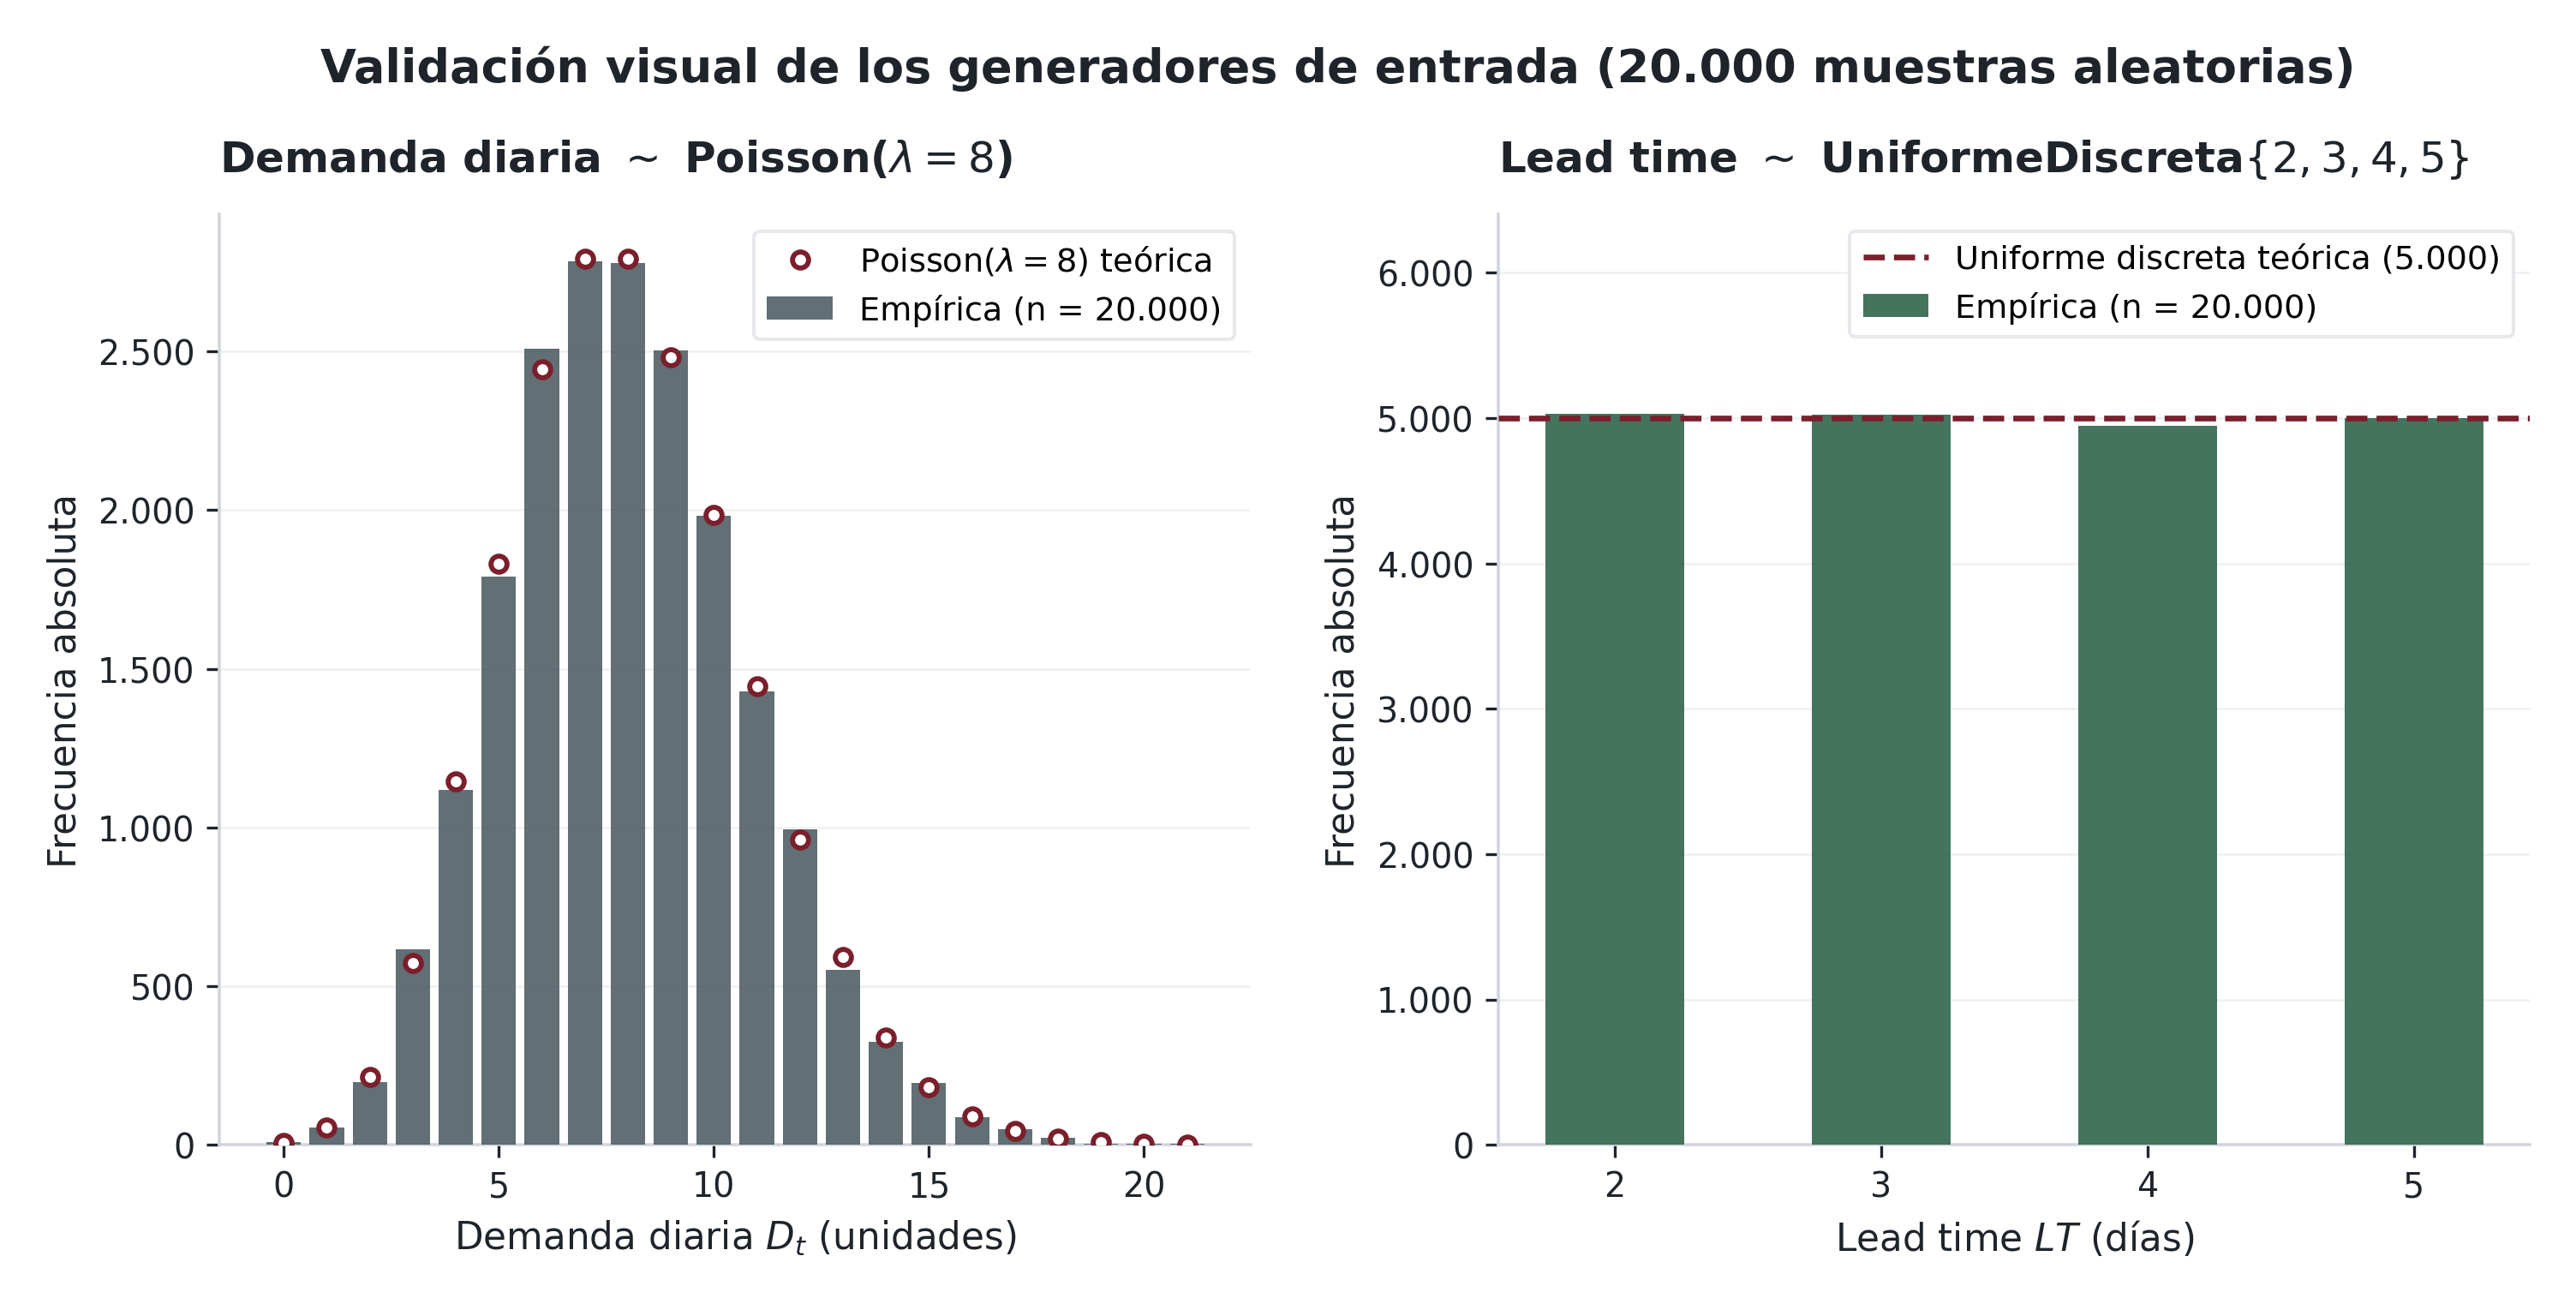

fig02_analisis_warmup.png


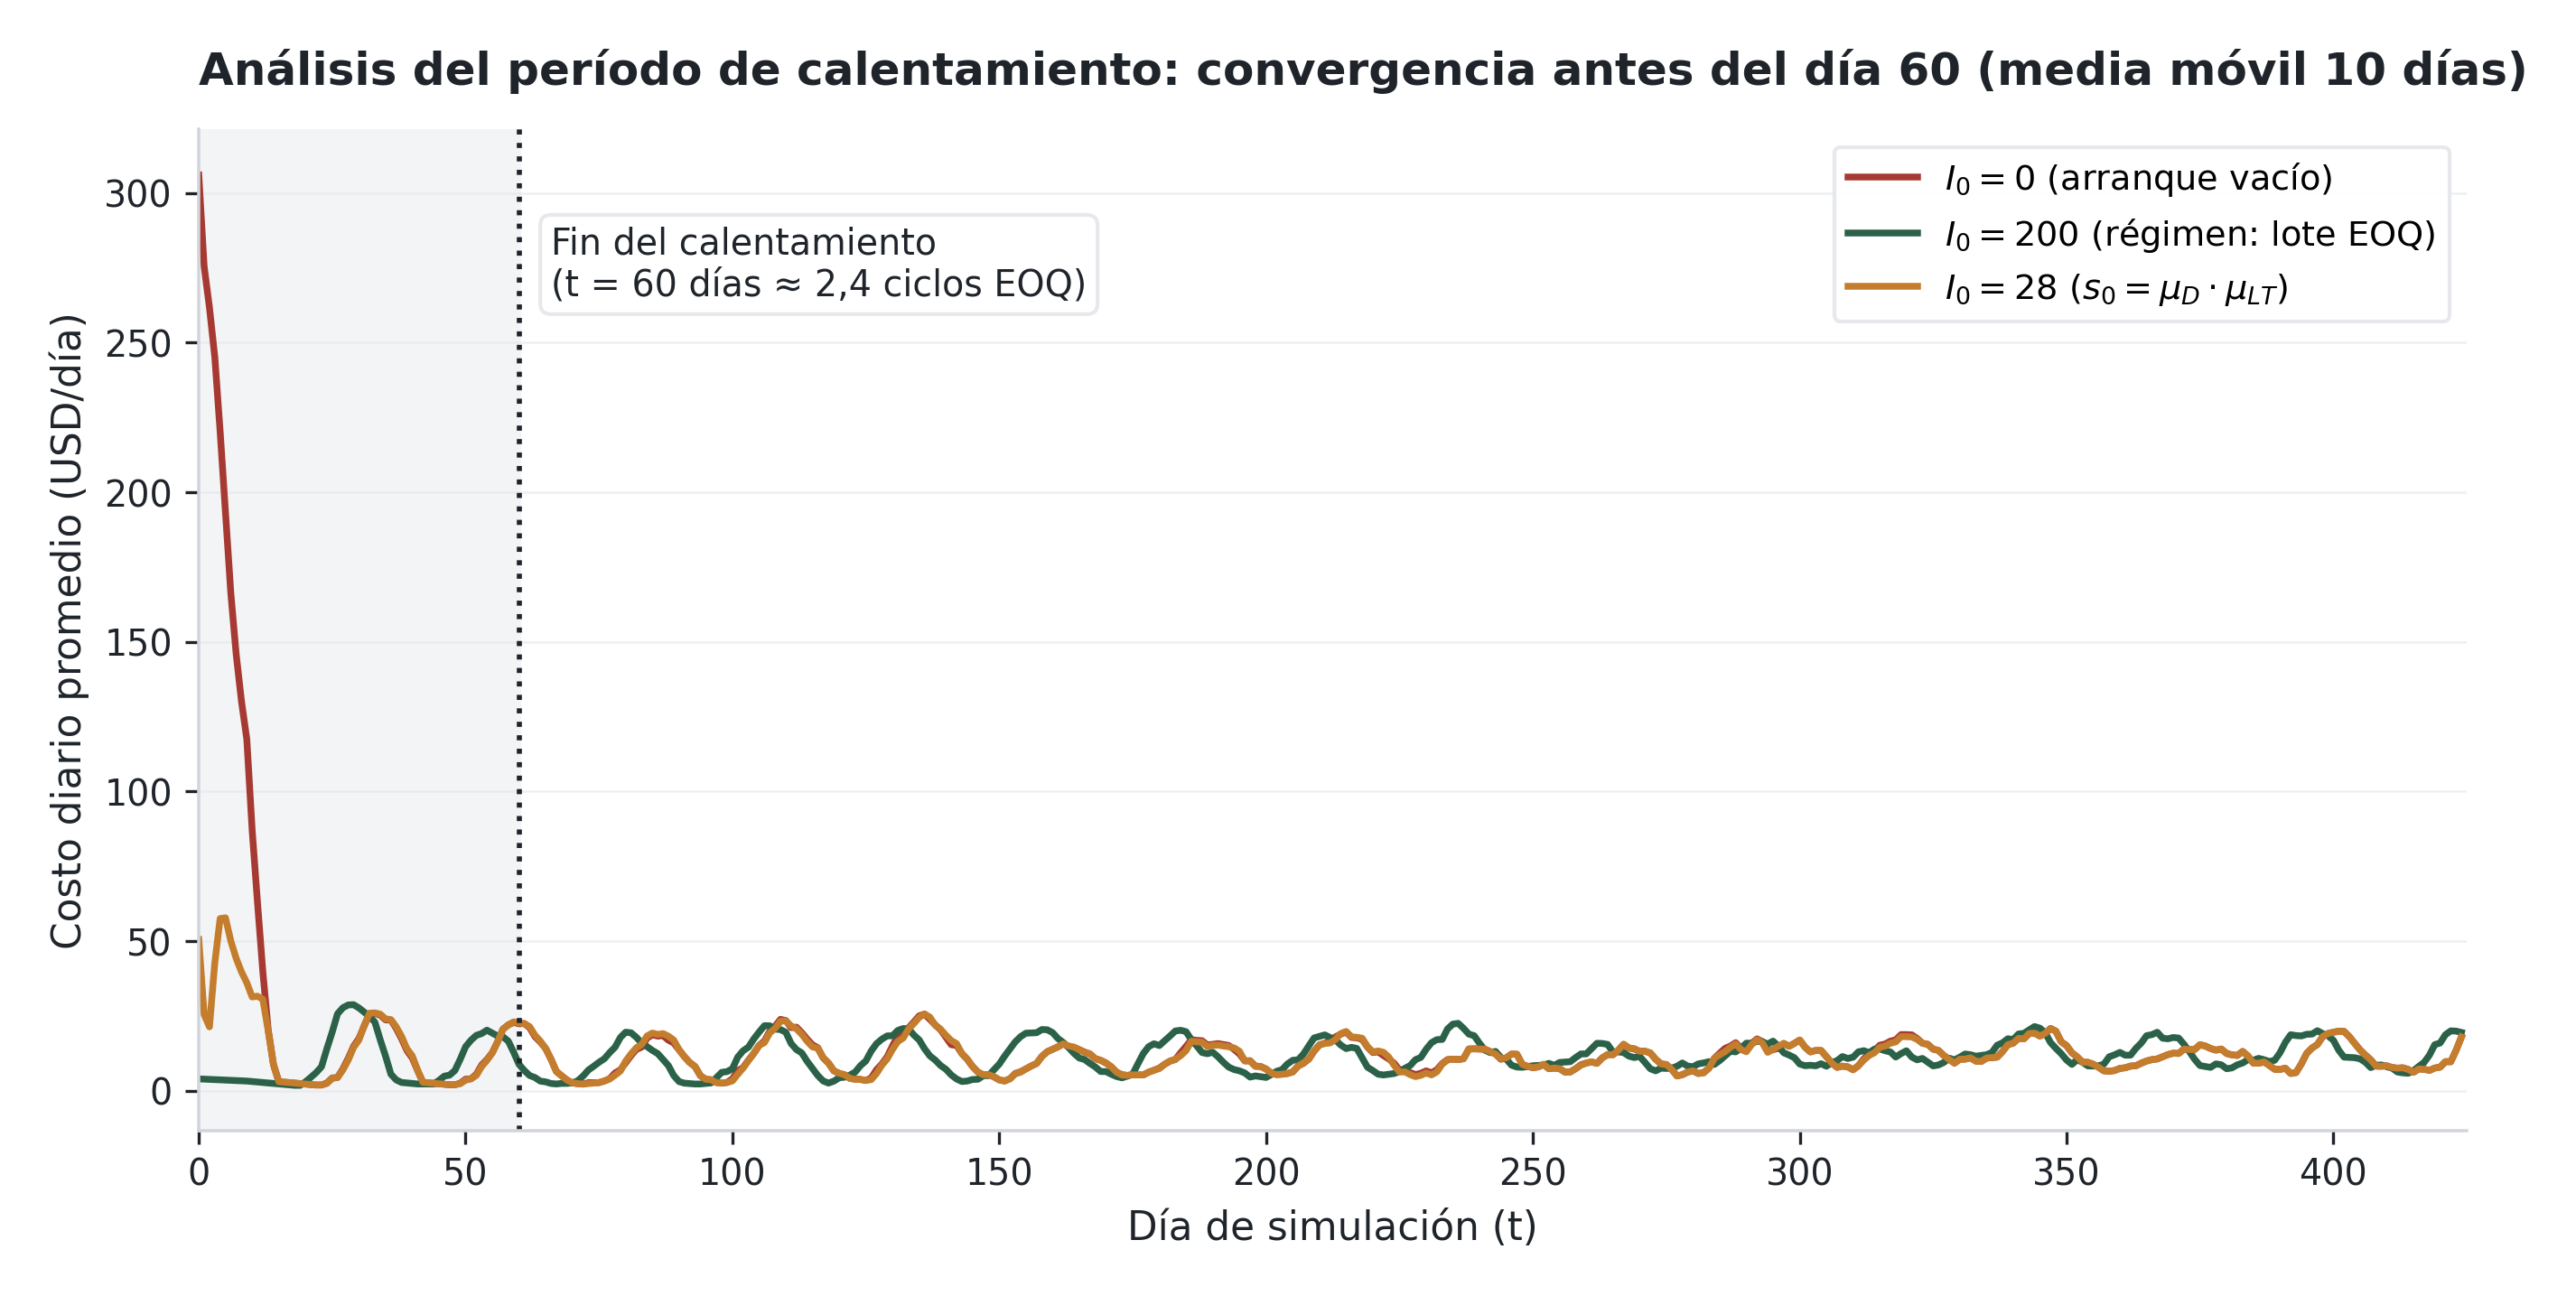

fig03_evolucion_inventario.png


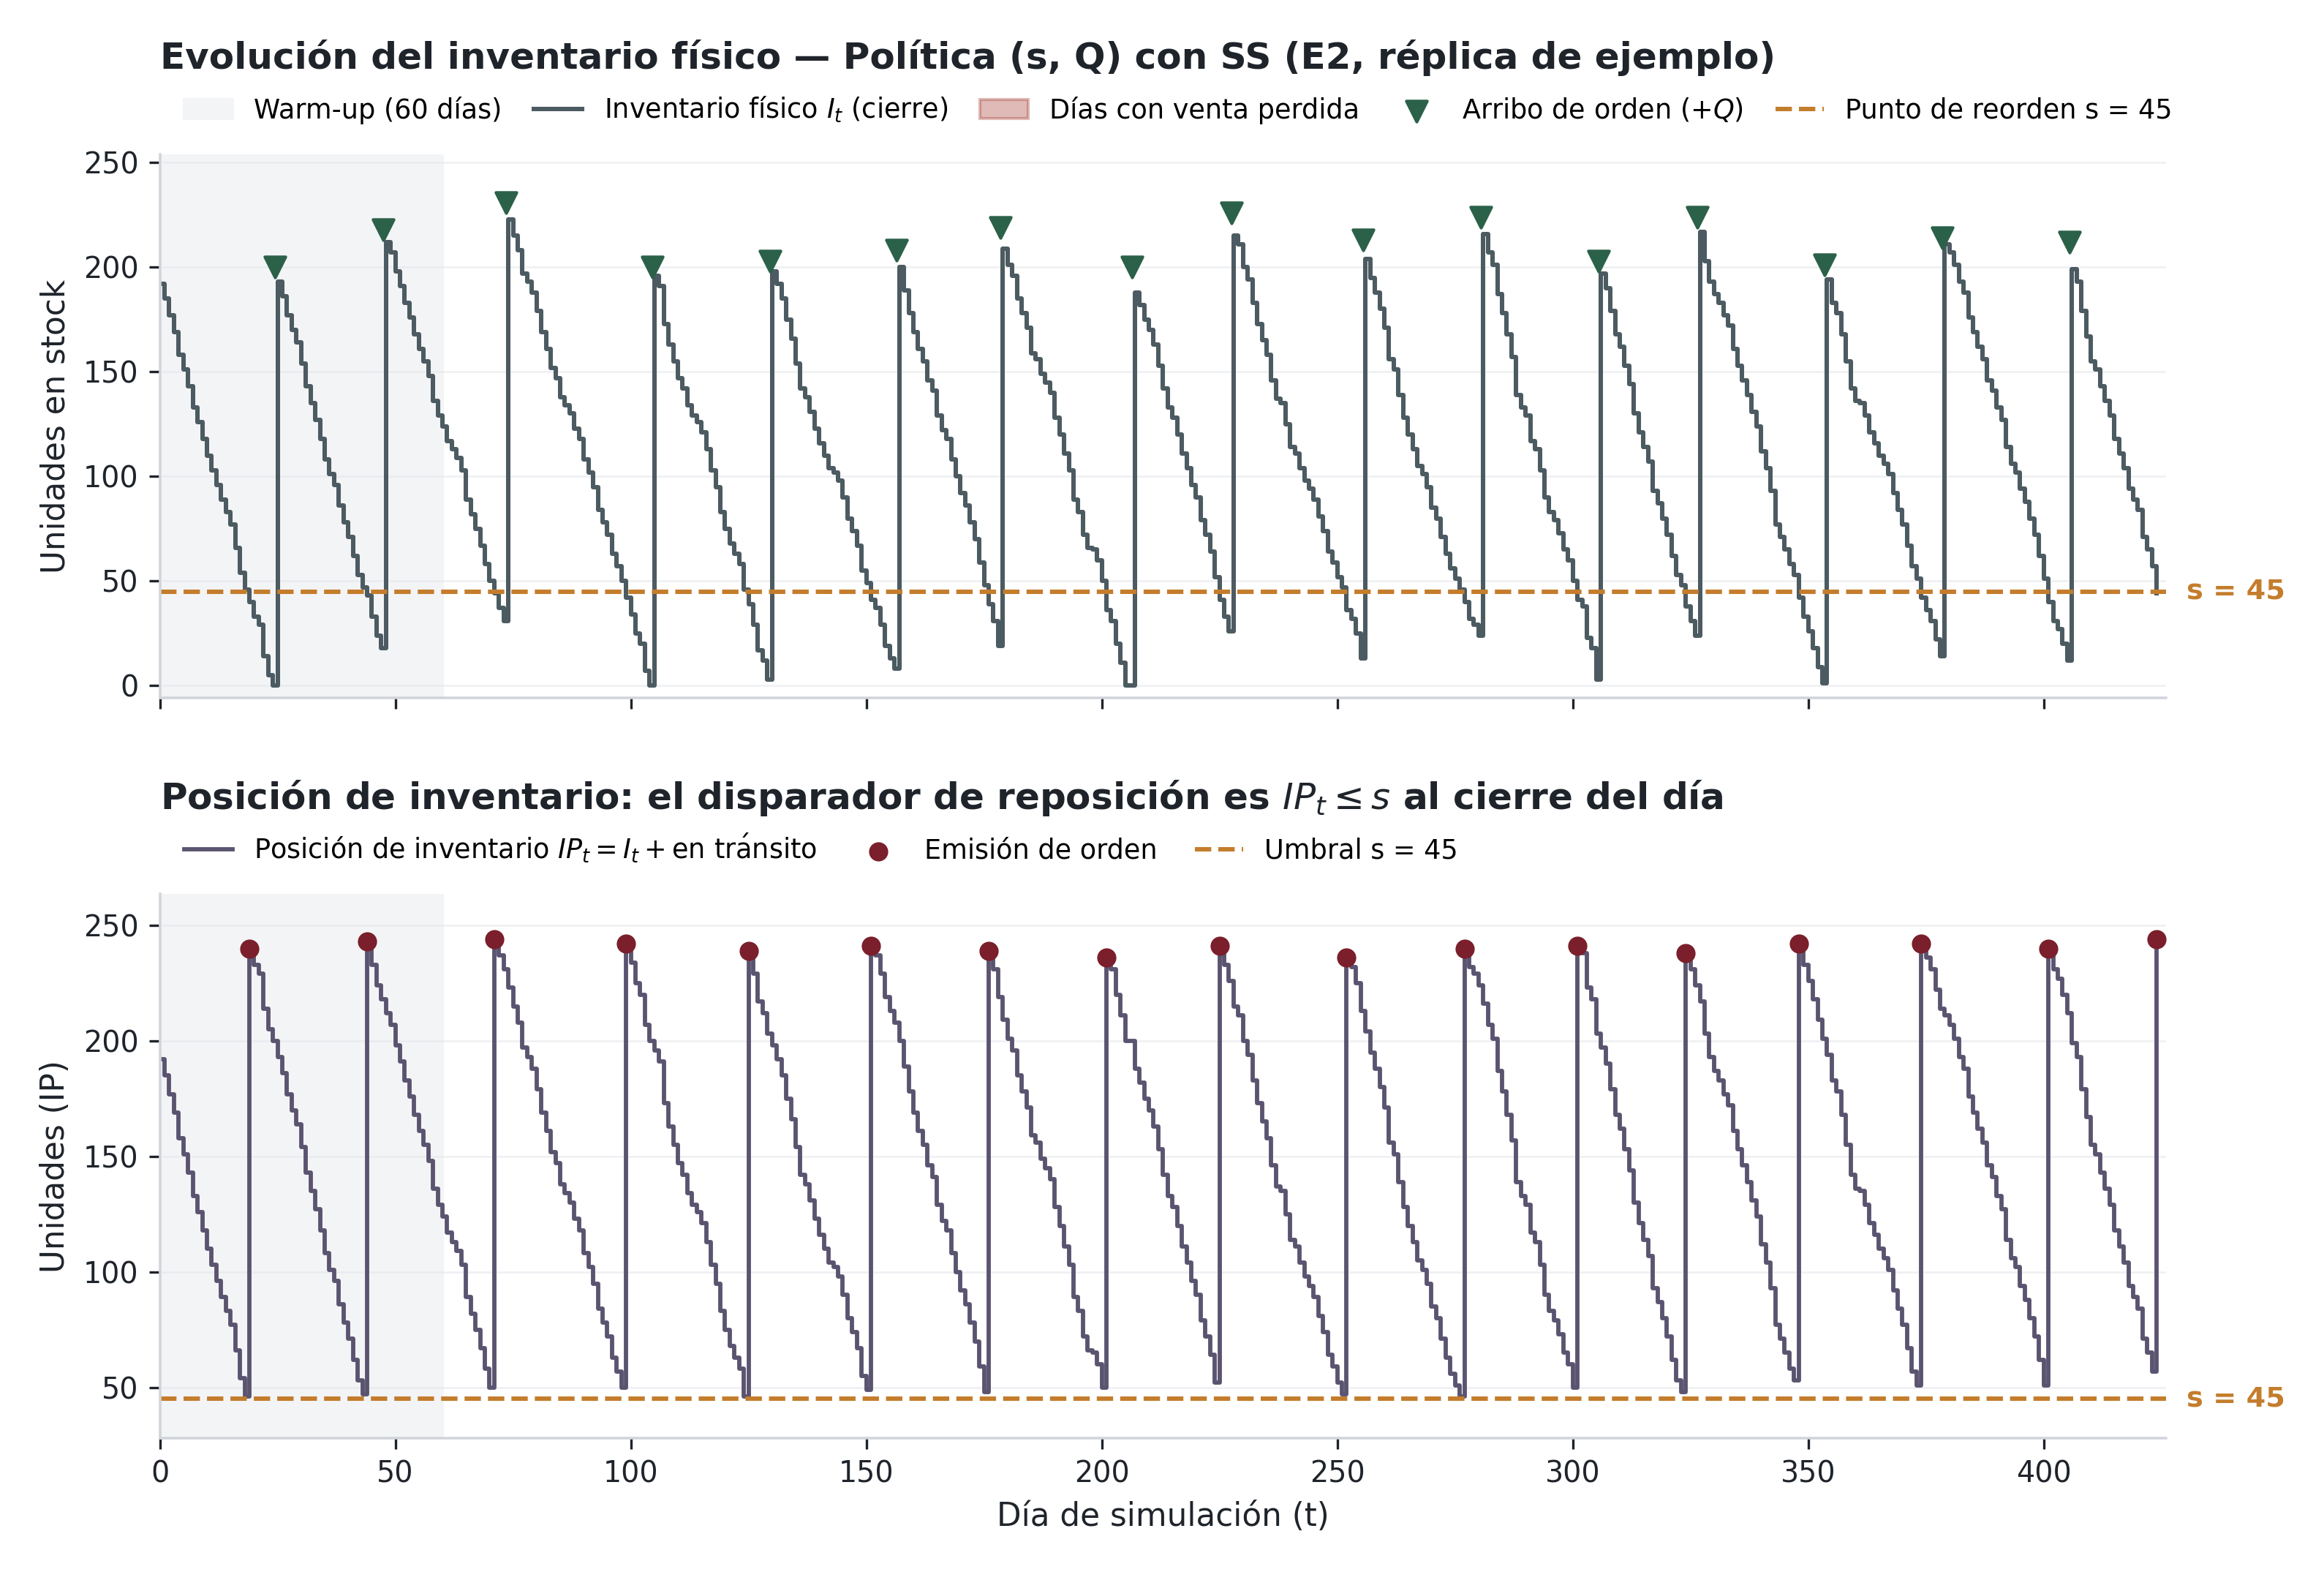

fig04_composicion_costos.png


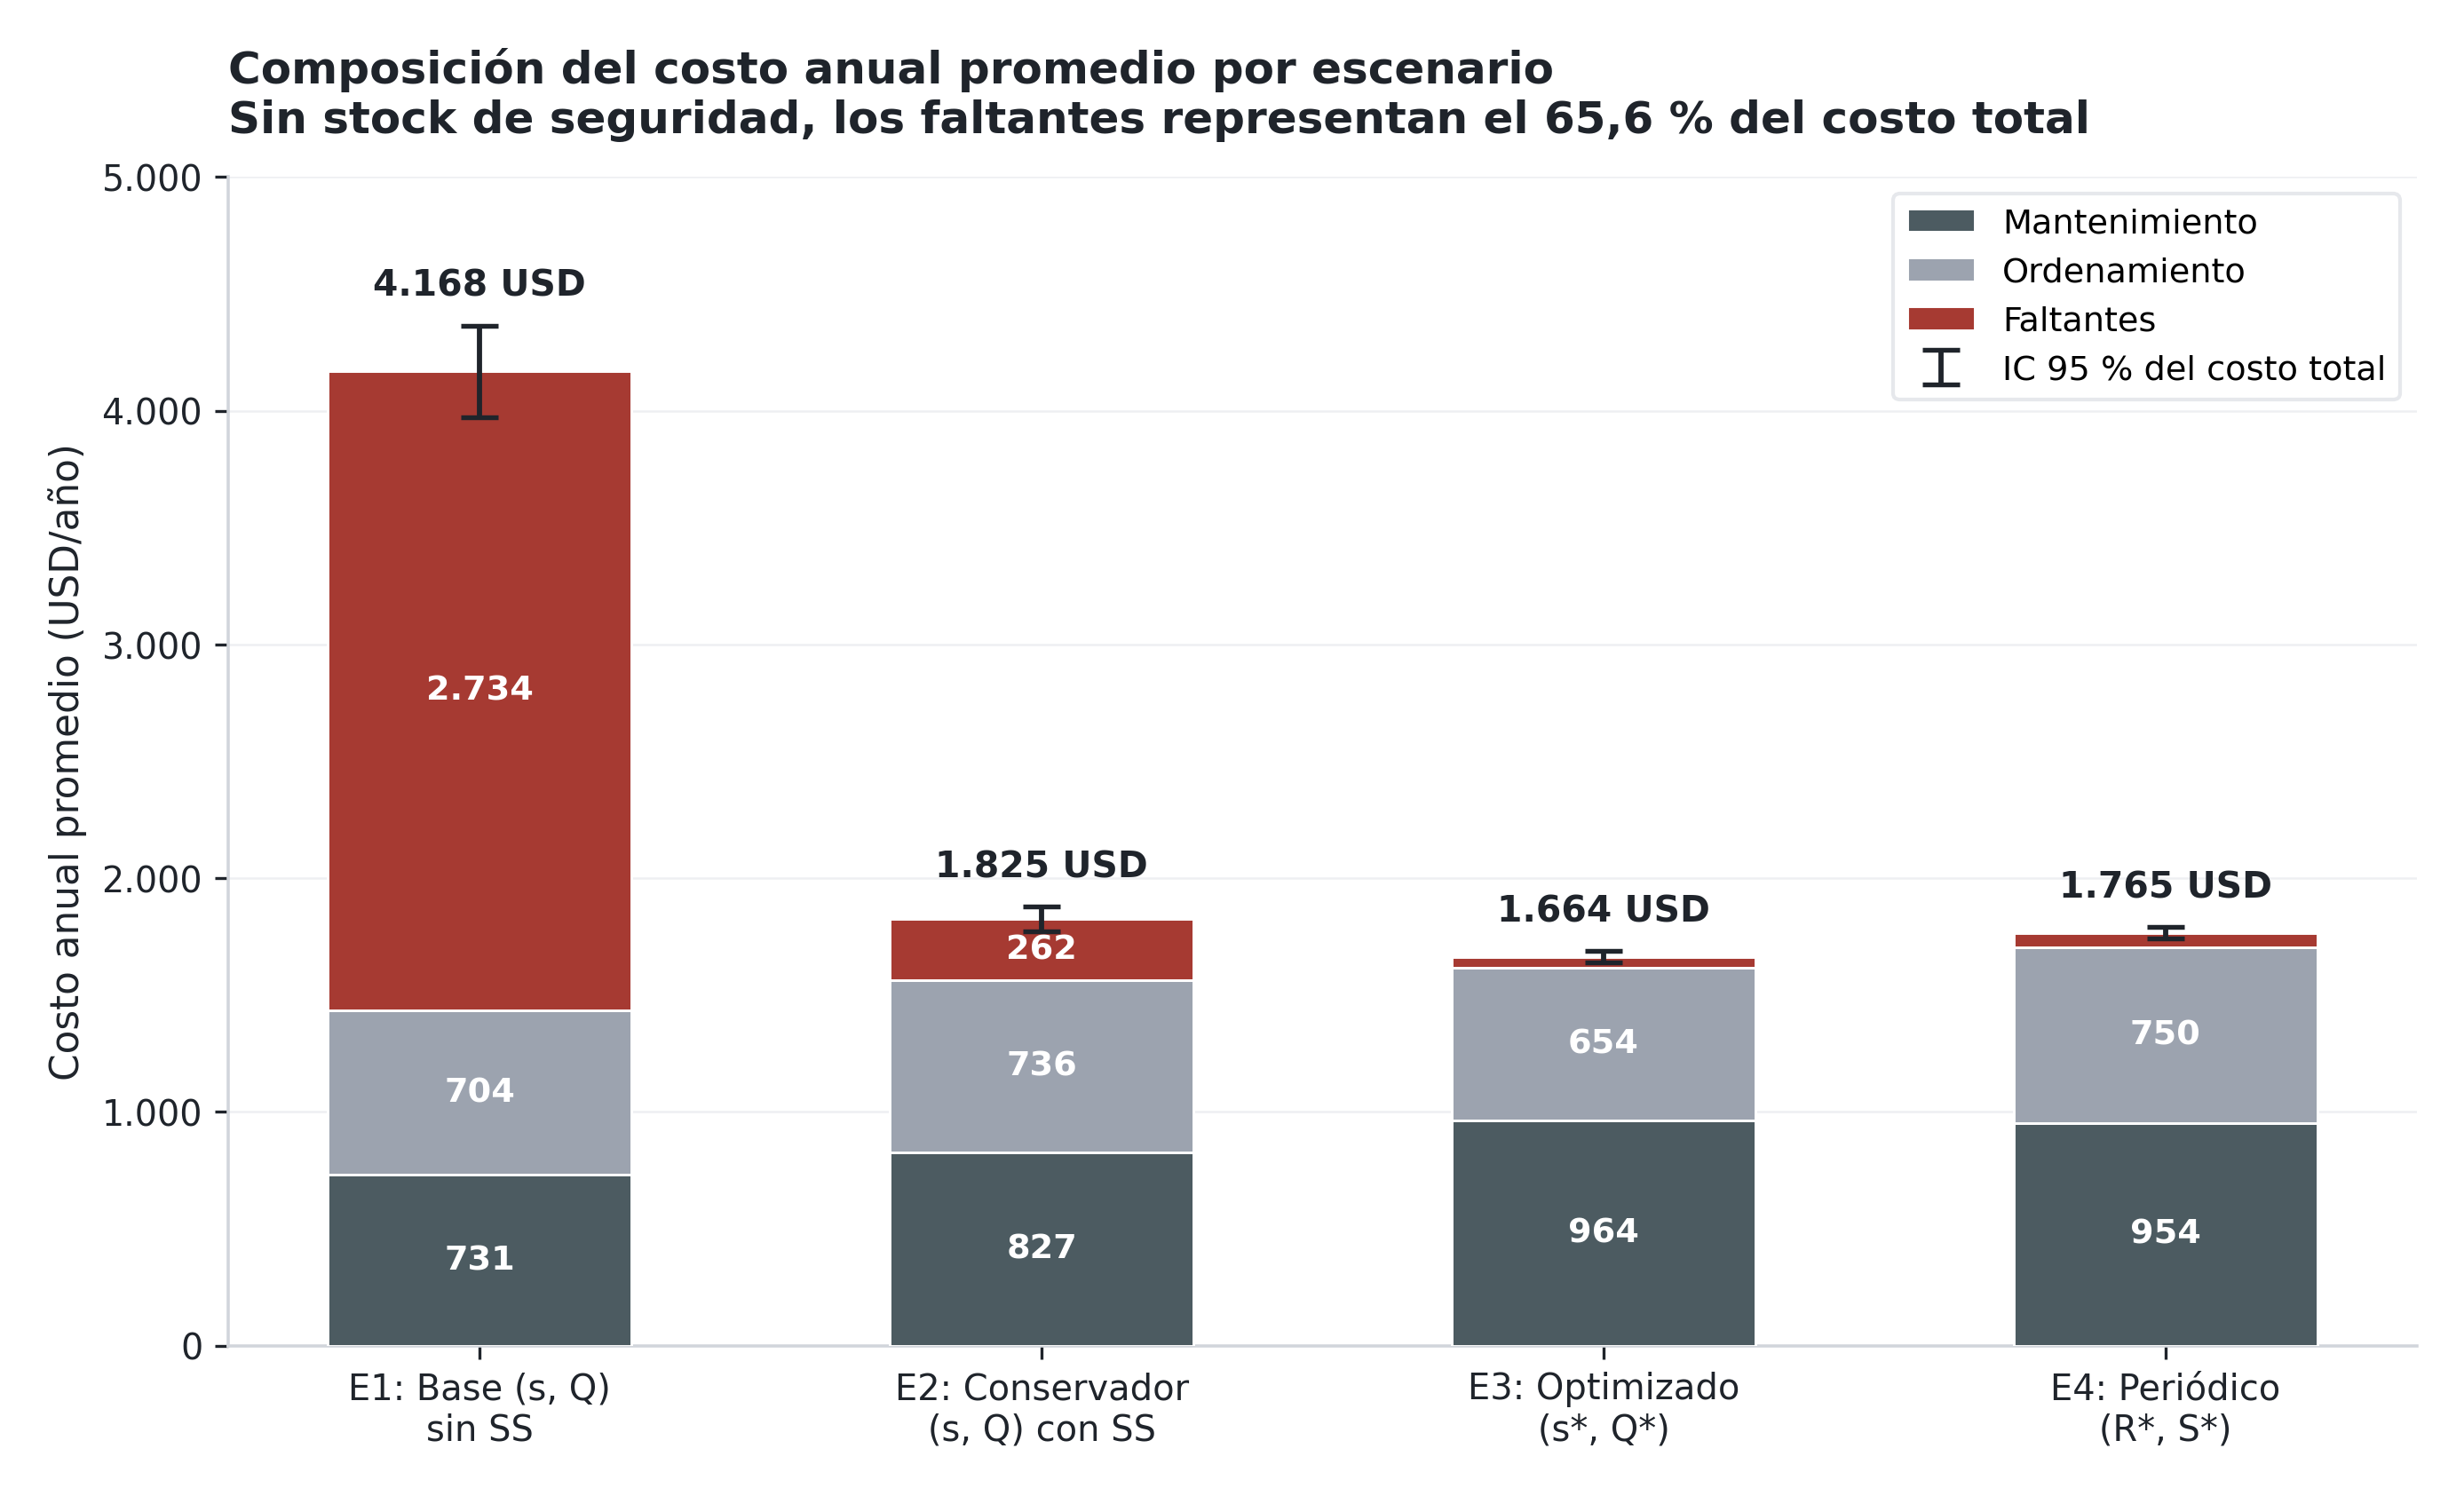

fig05_boxplots_costo_servicio.png


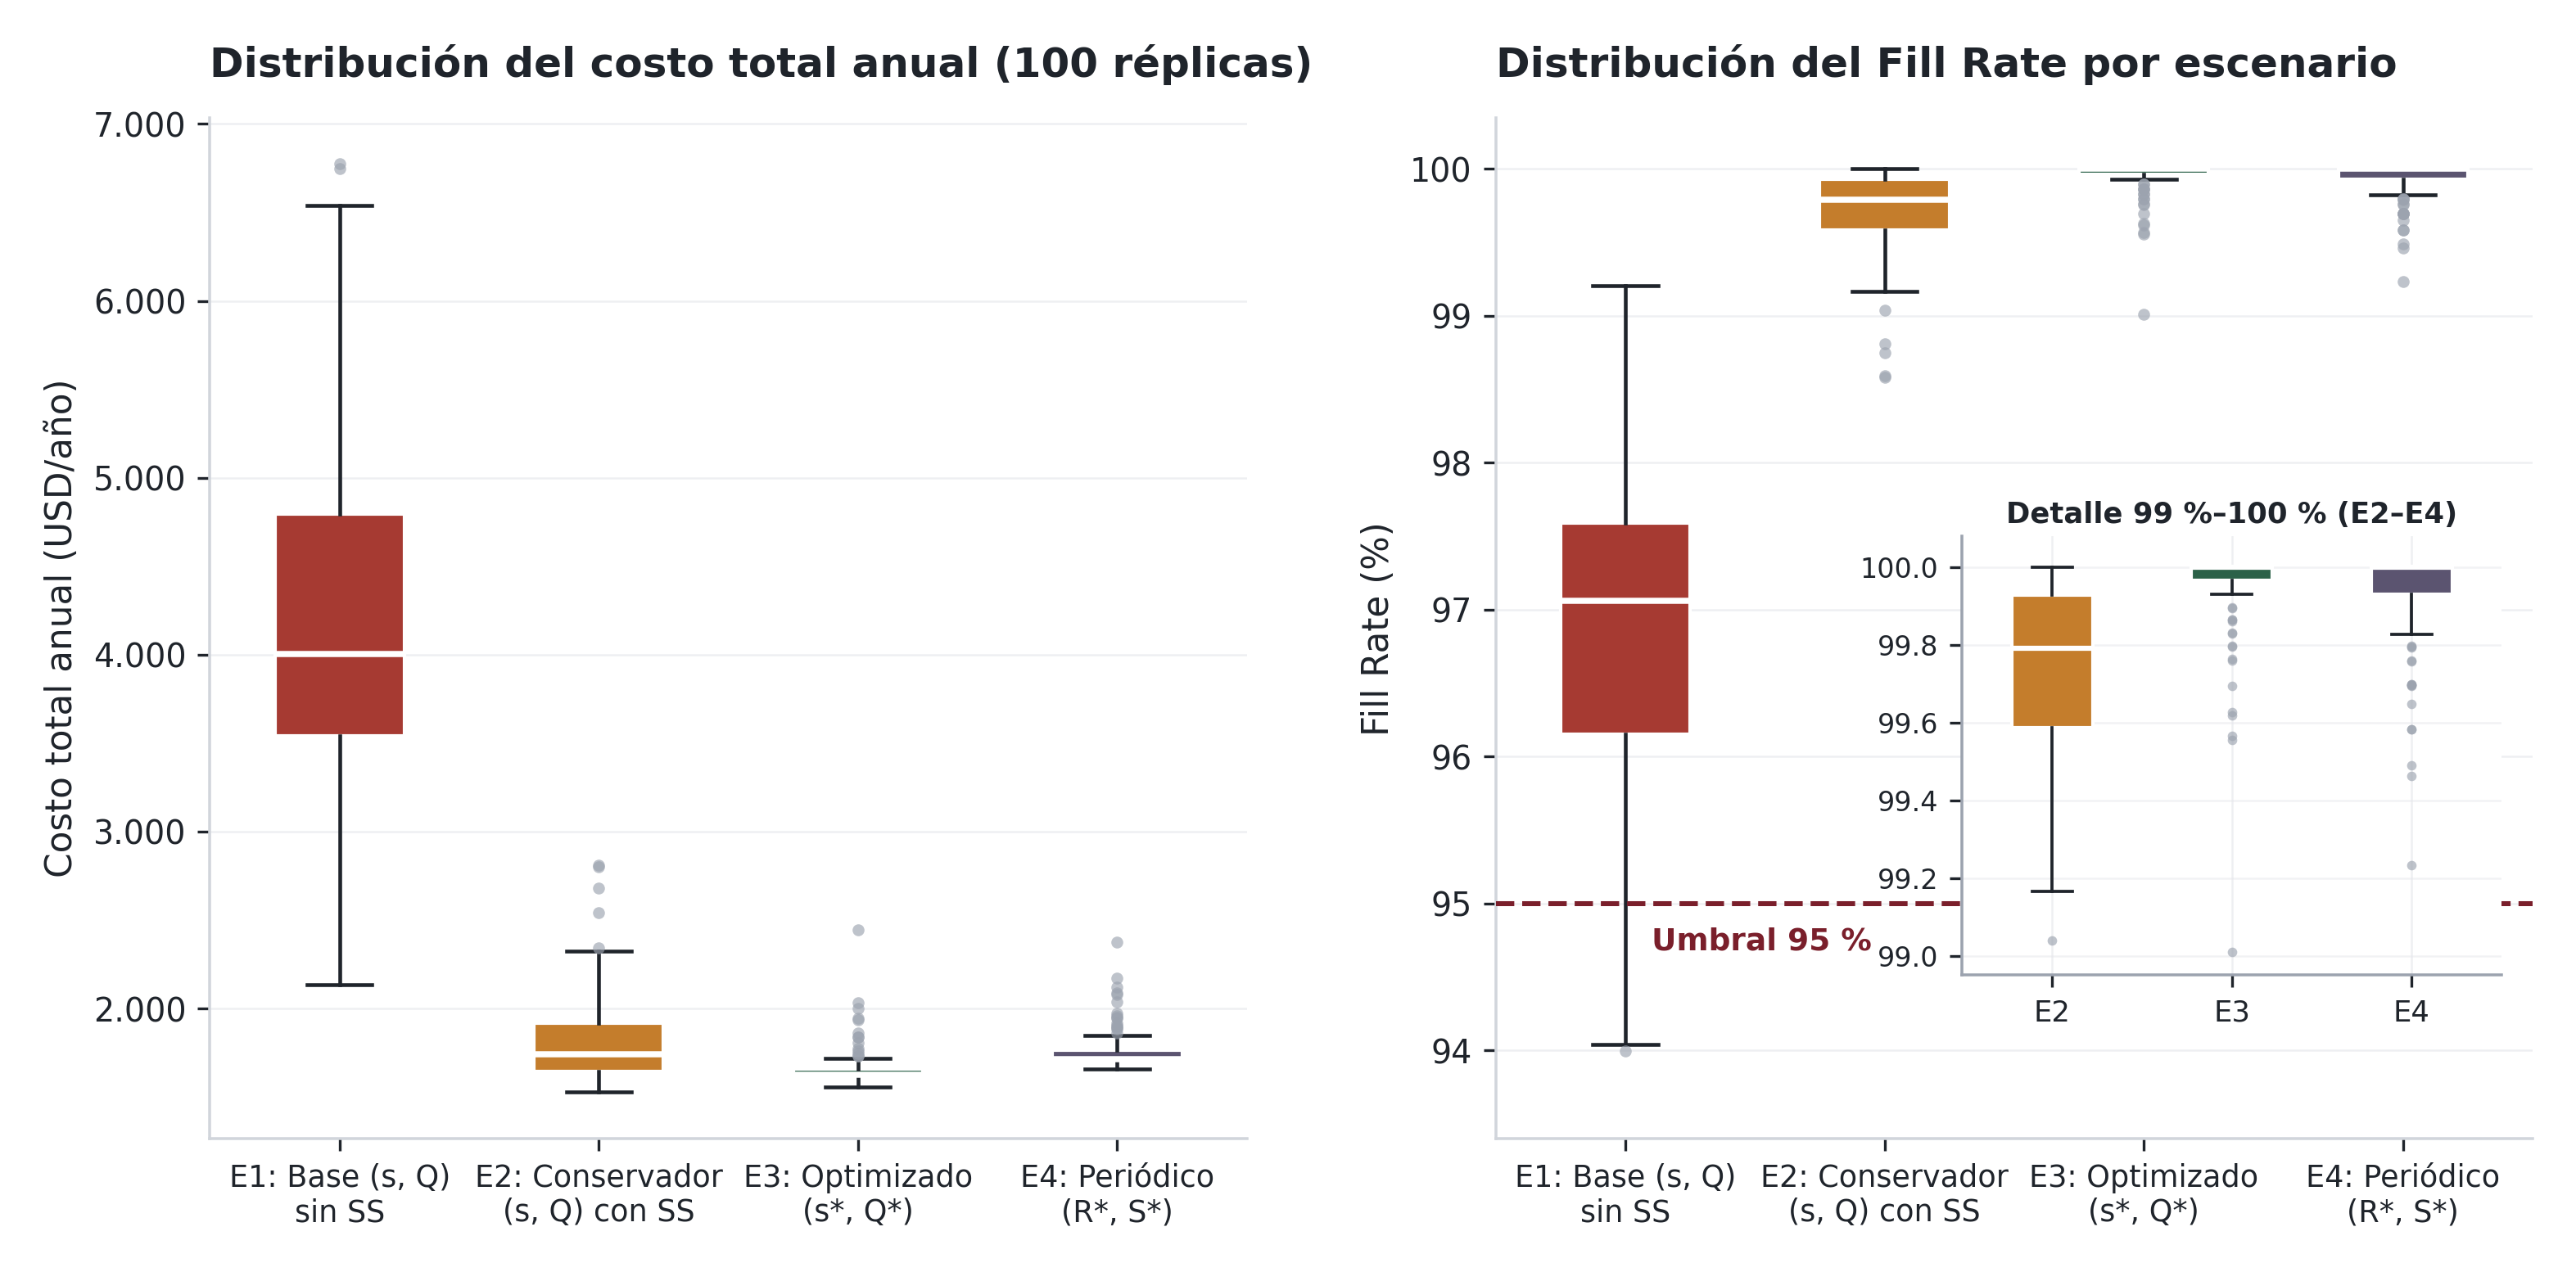

fig06_intervalos_confianza.png


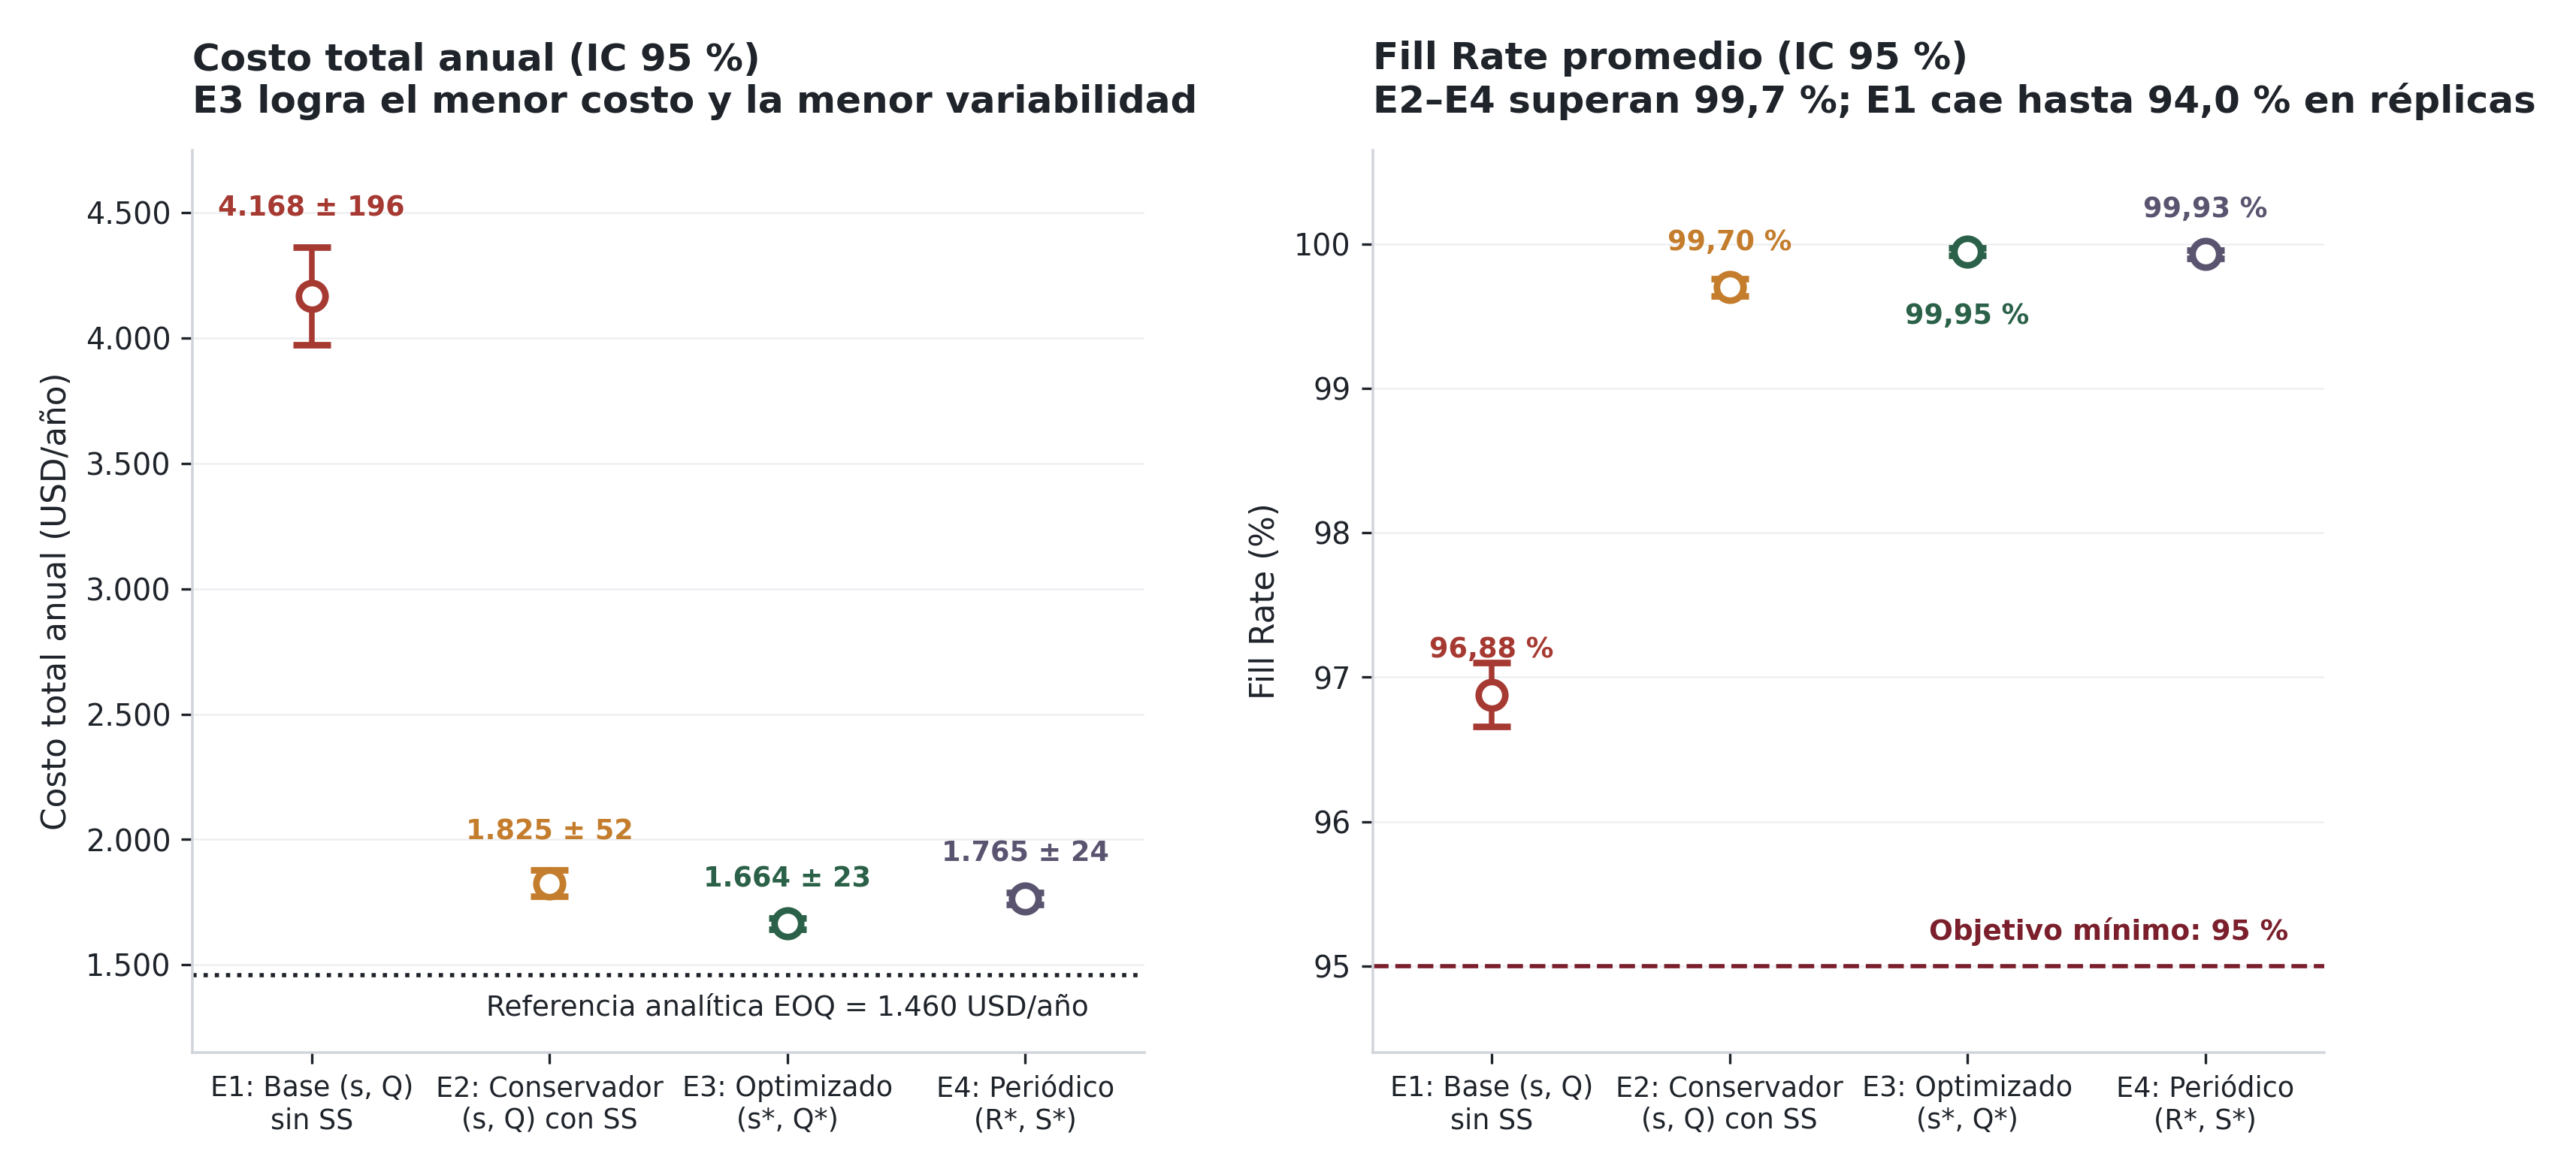

fig07_heatmap_sQ.png


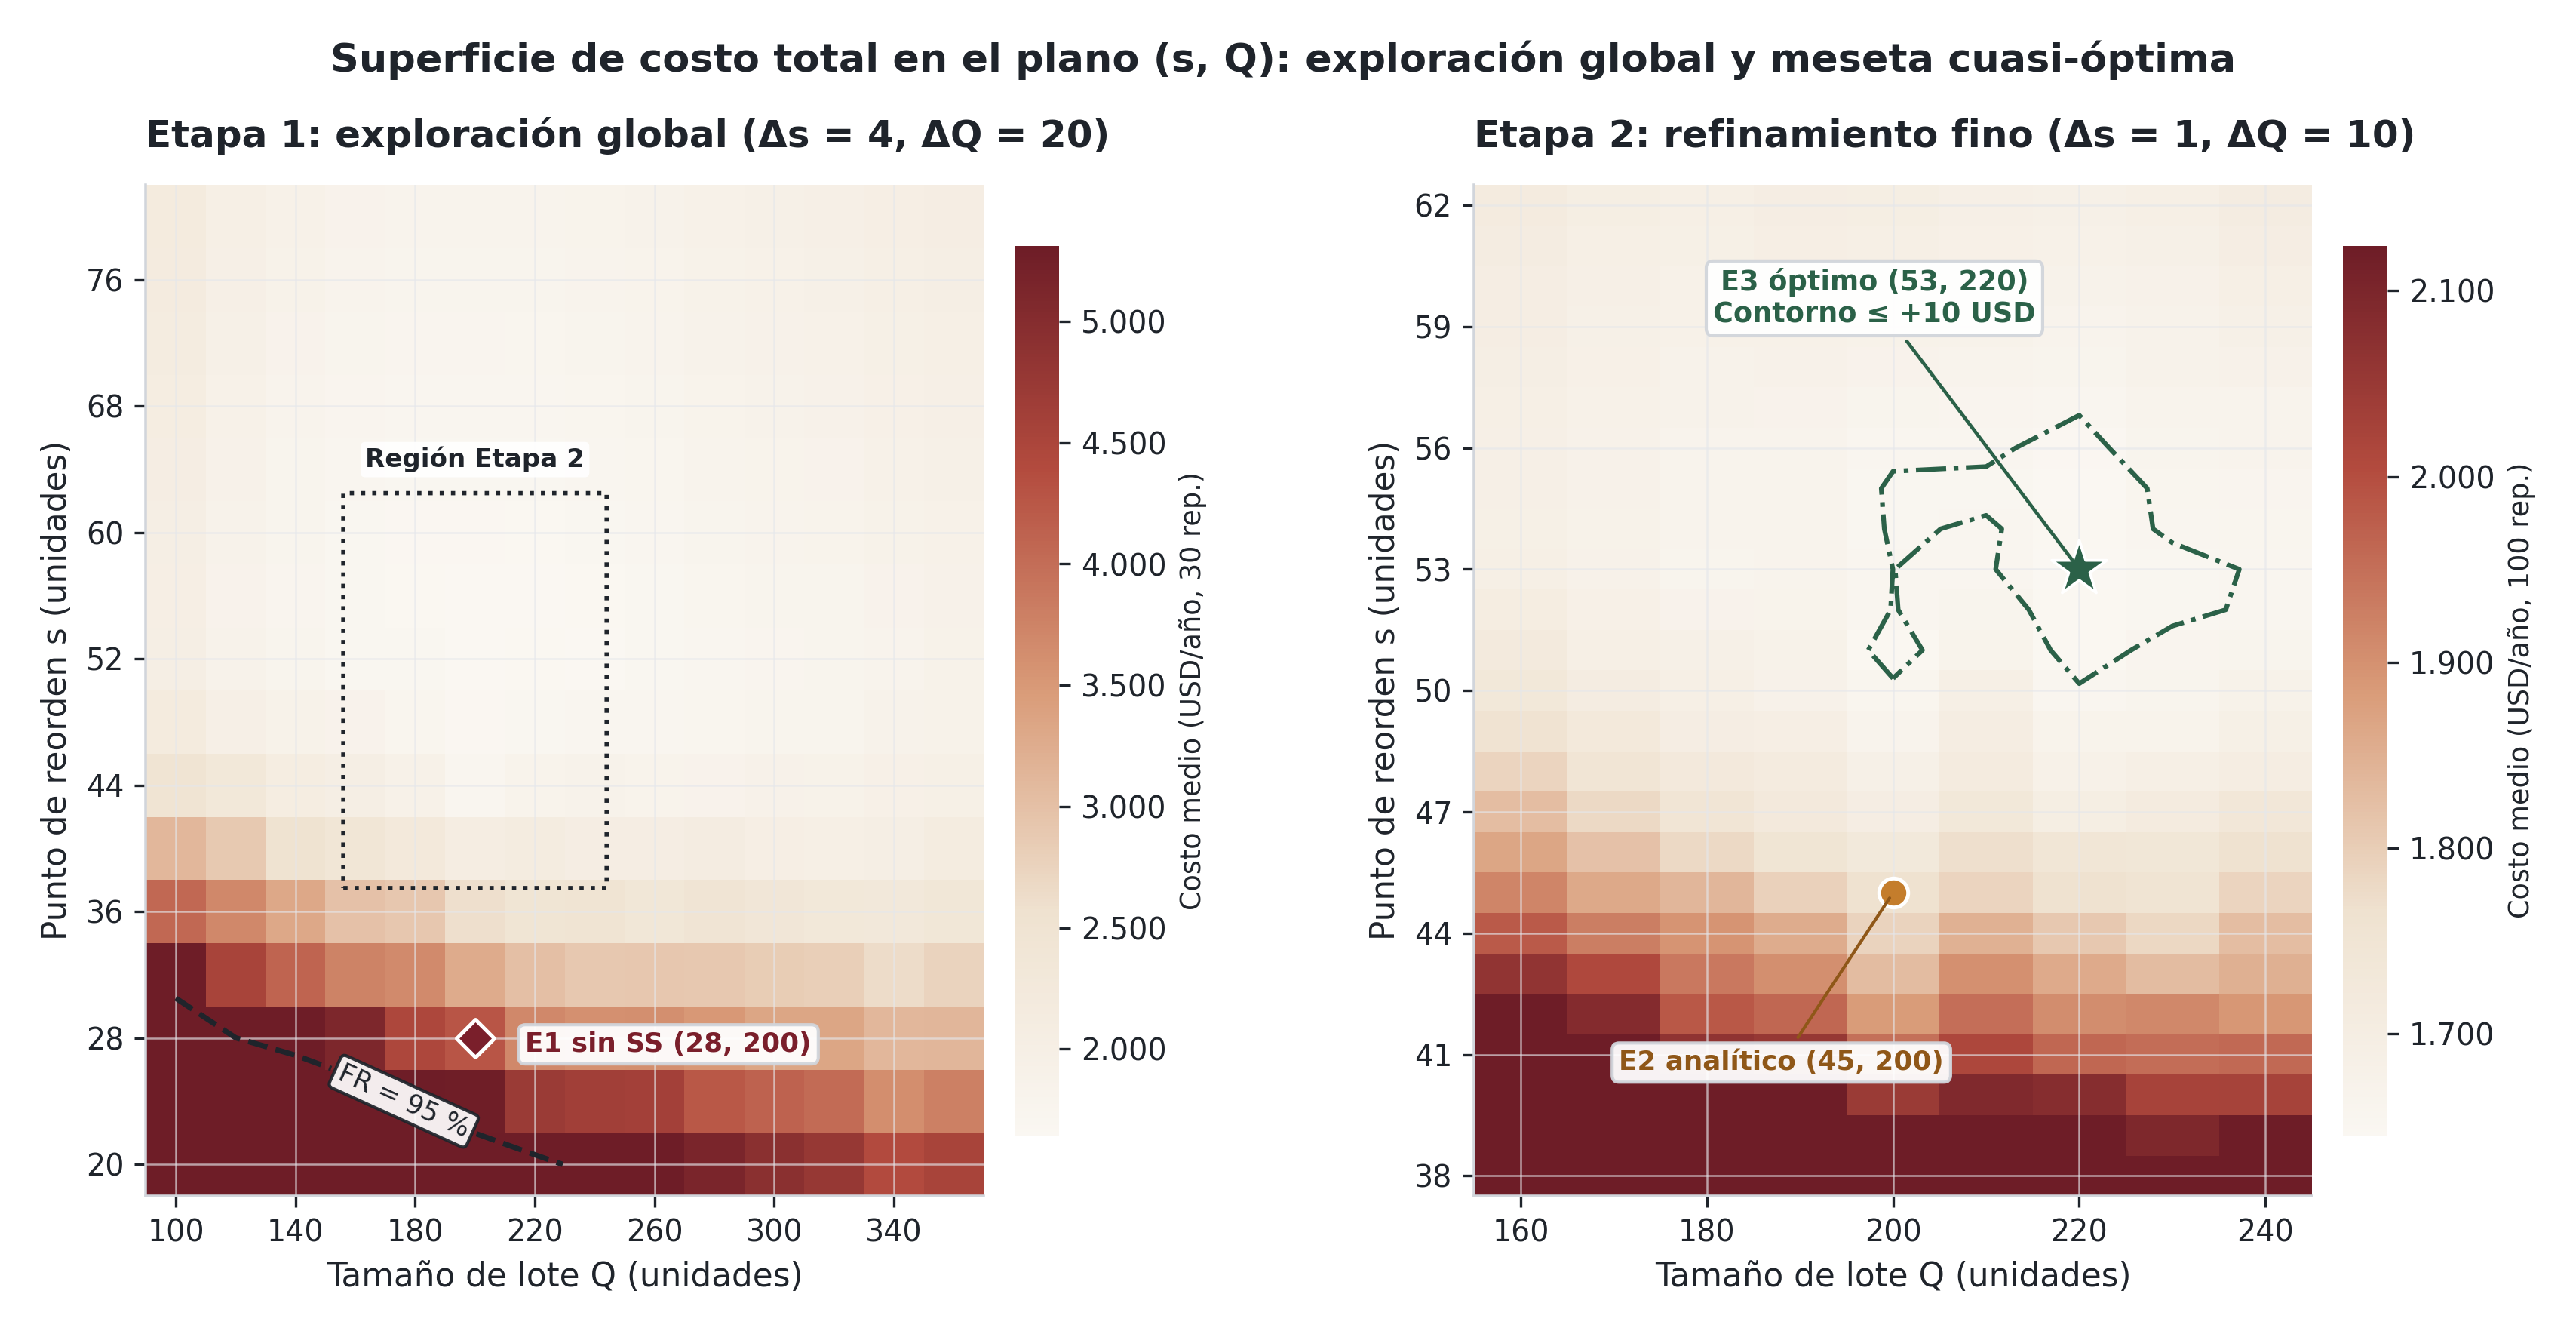

fig08_diagrama_flujo_sistema.png


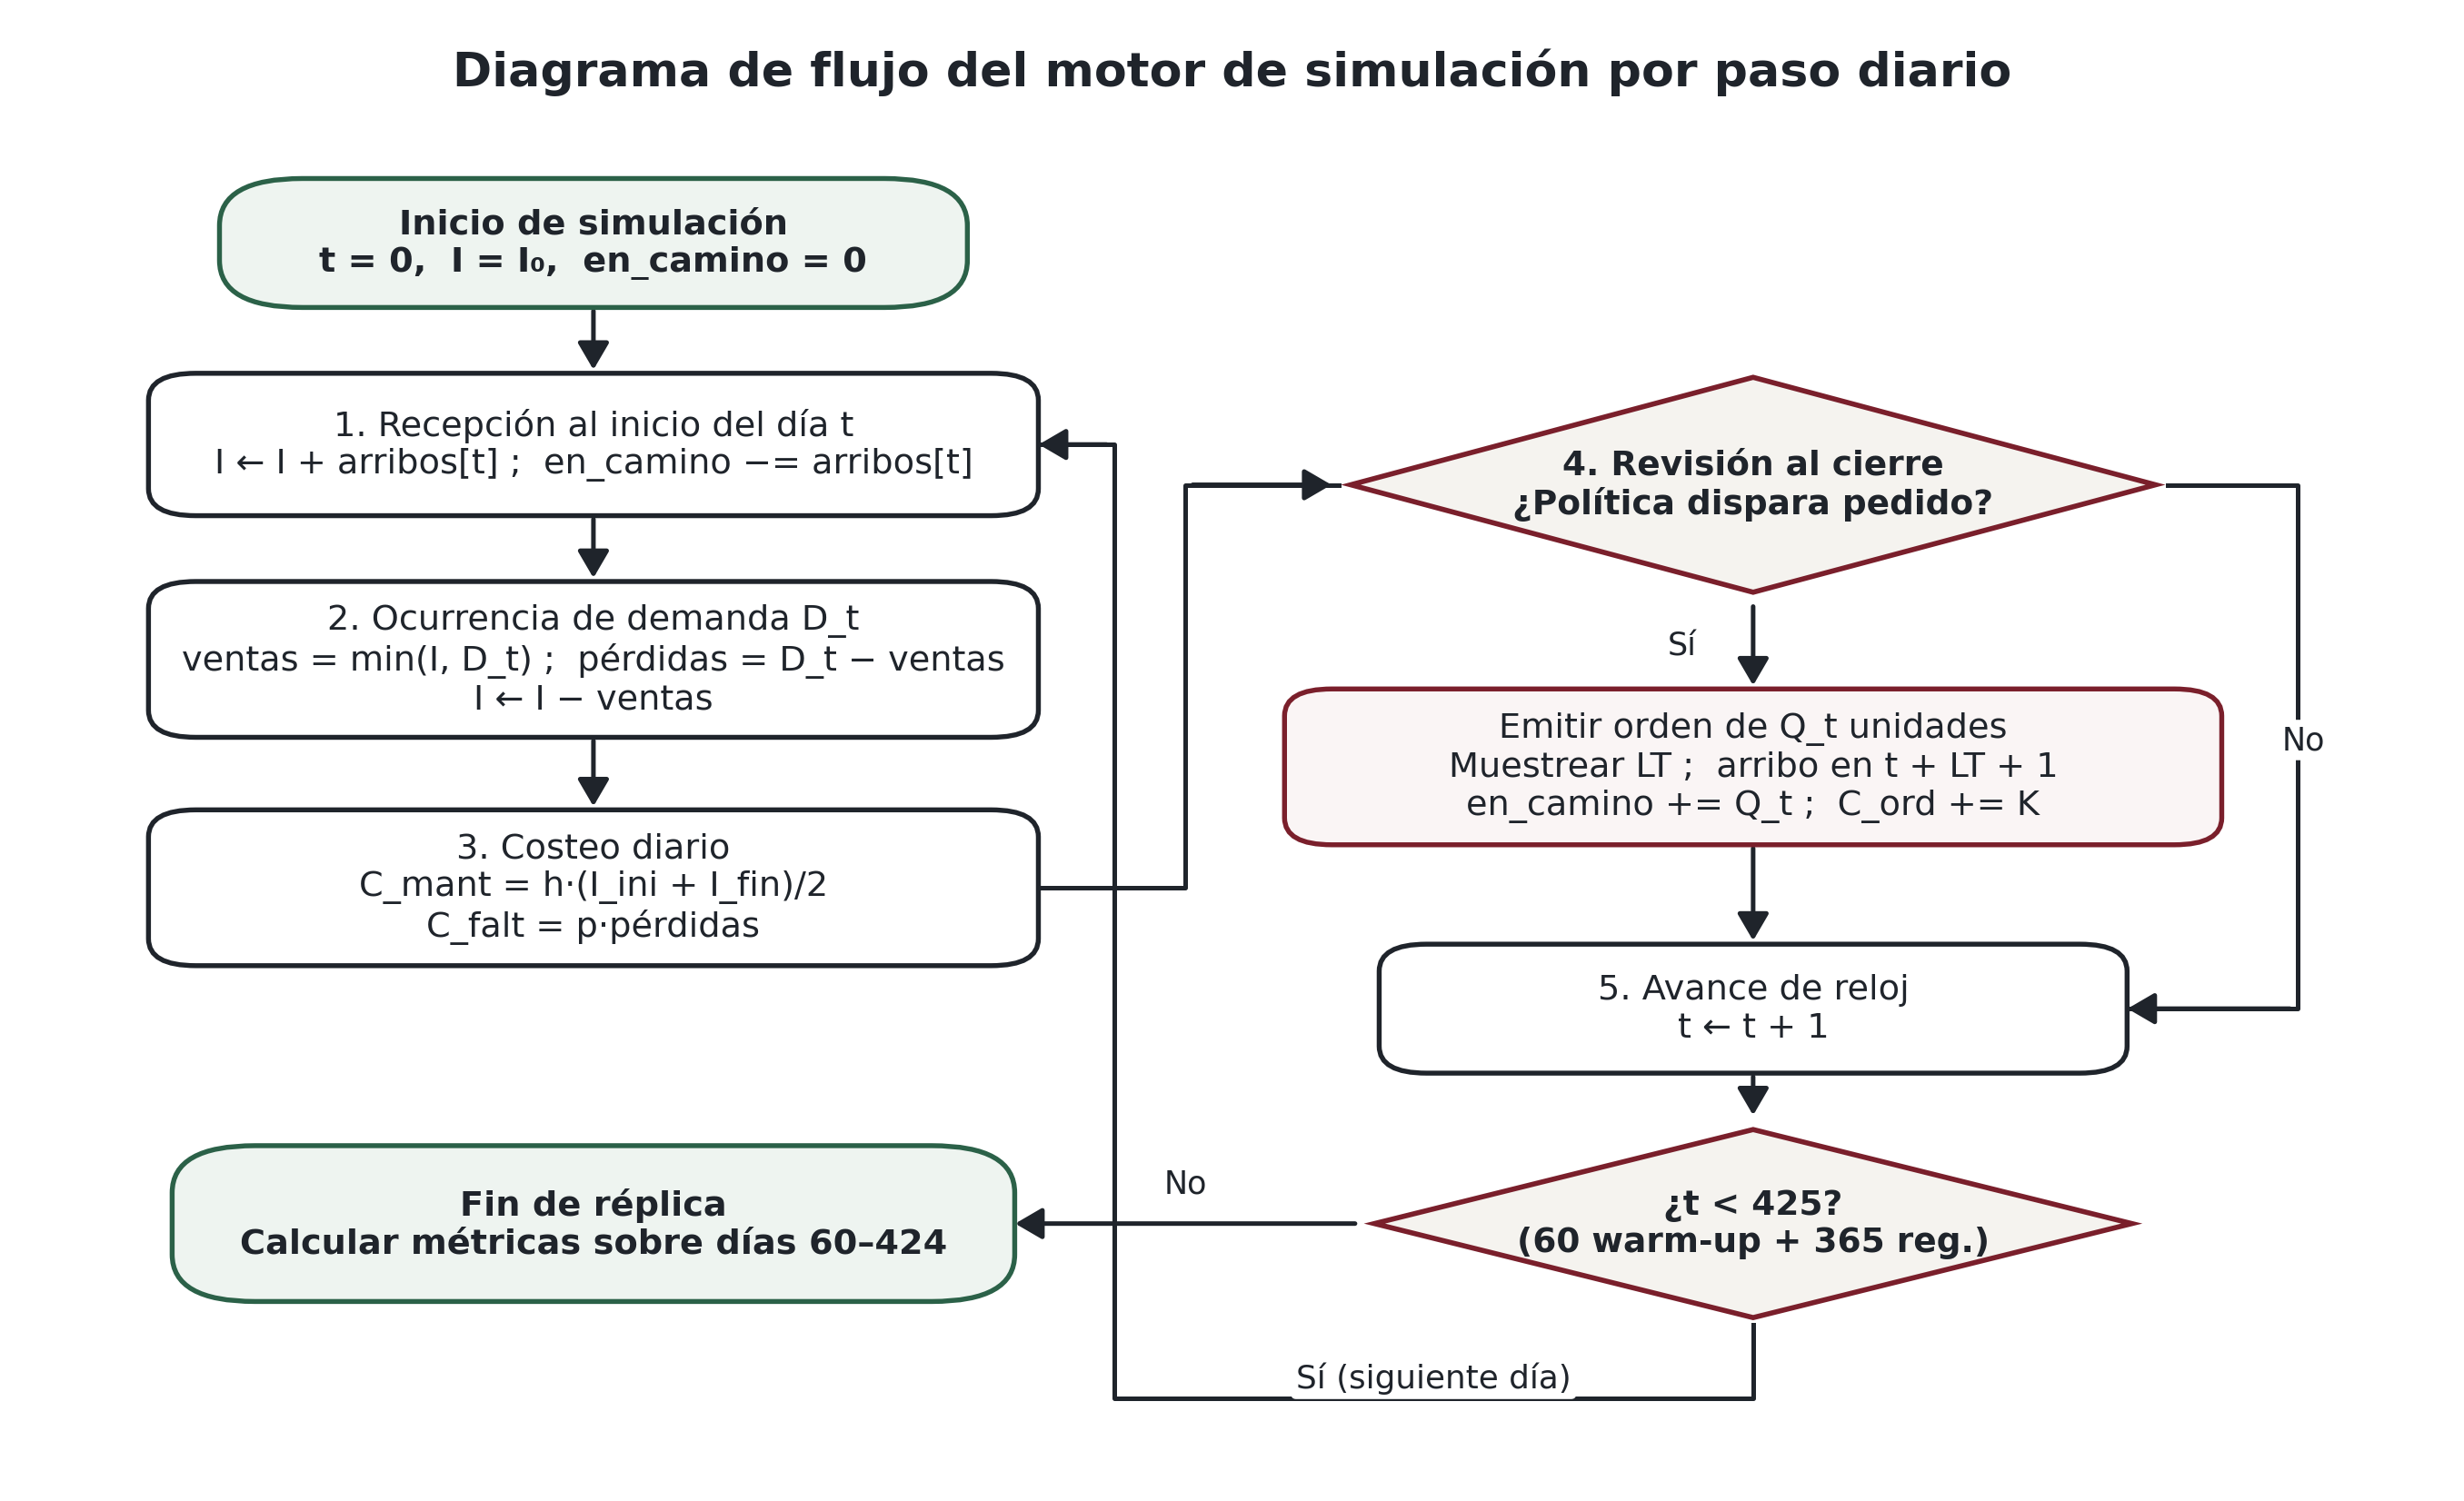

fig09_diagrama_logica_politicas.png


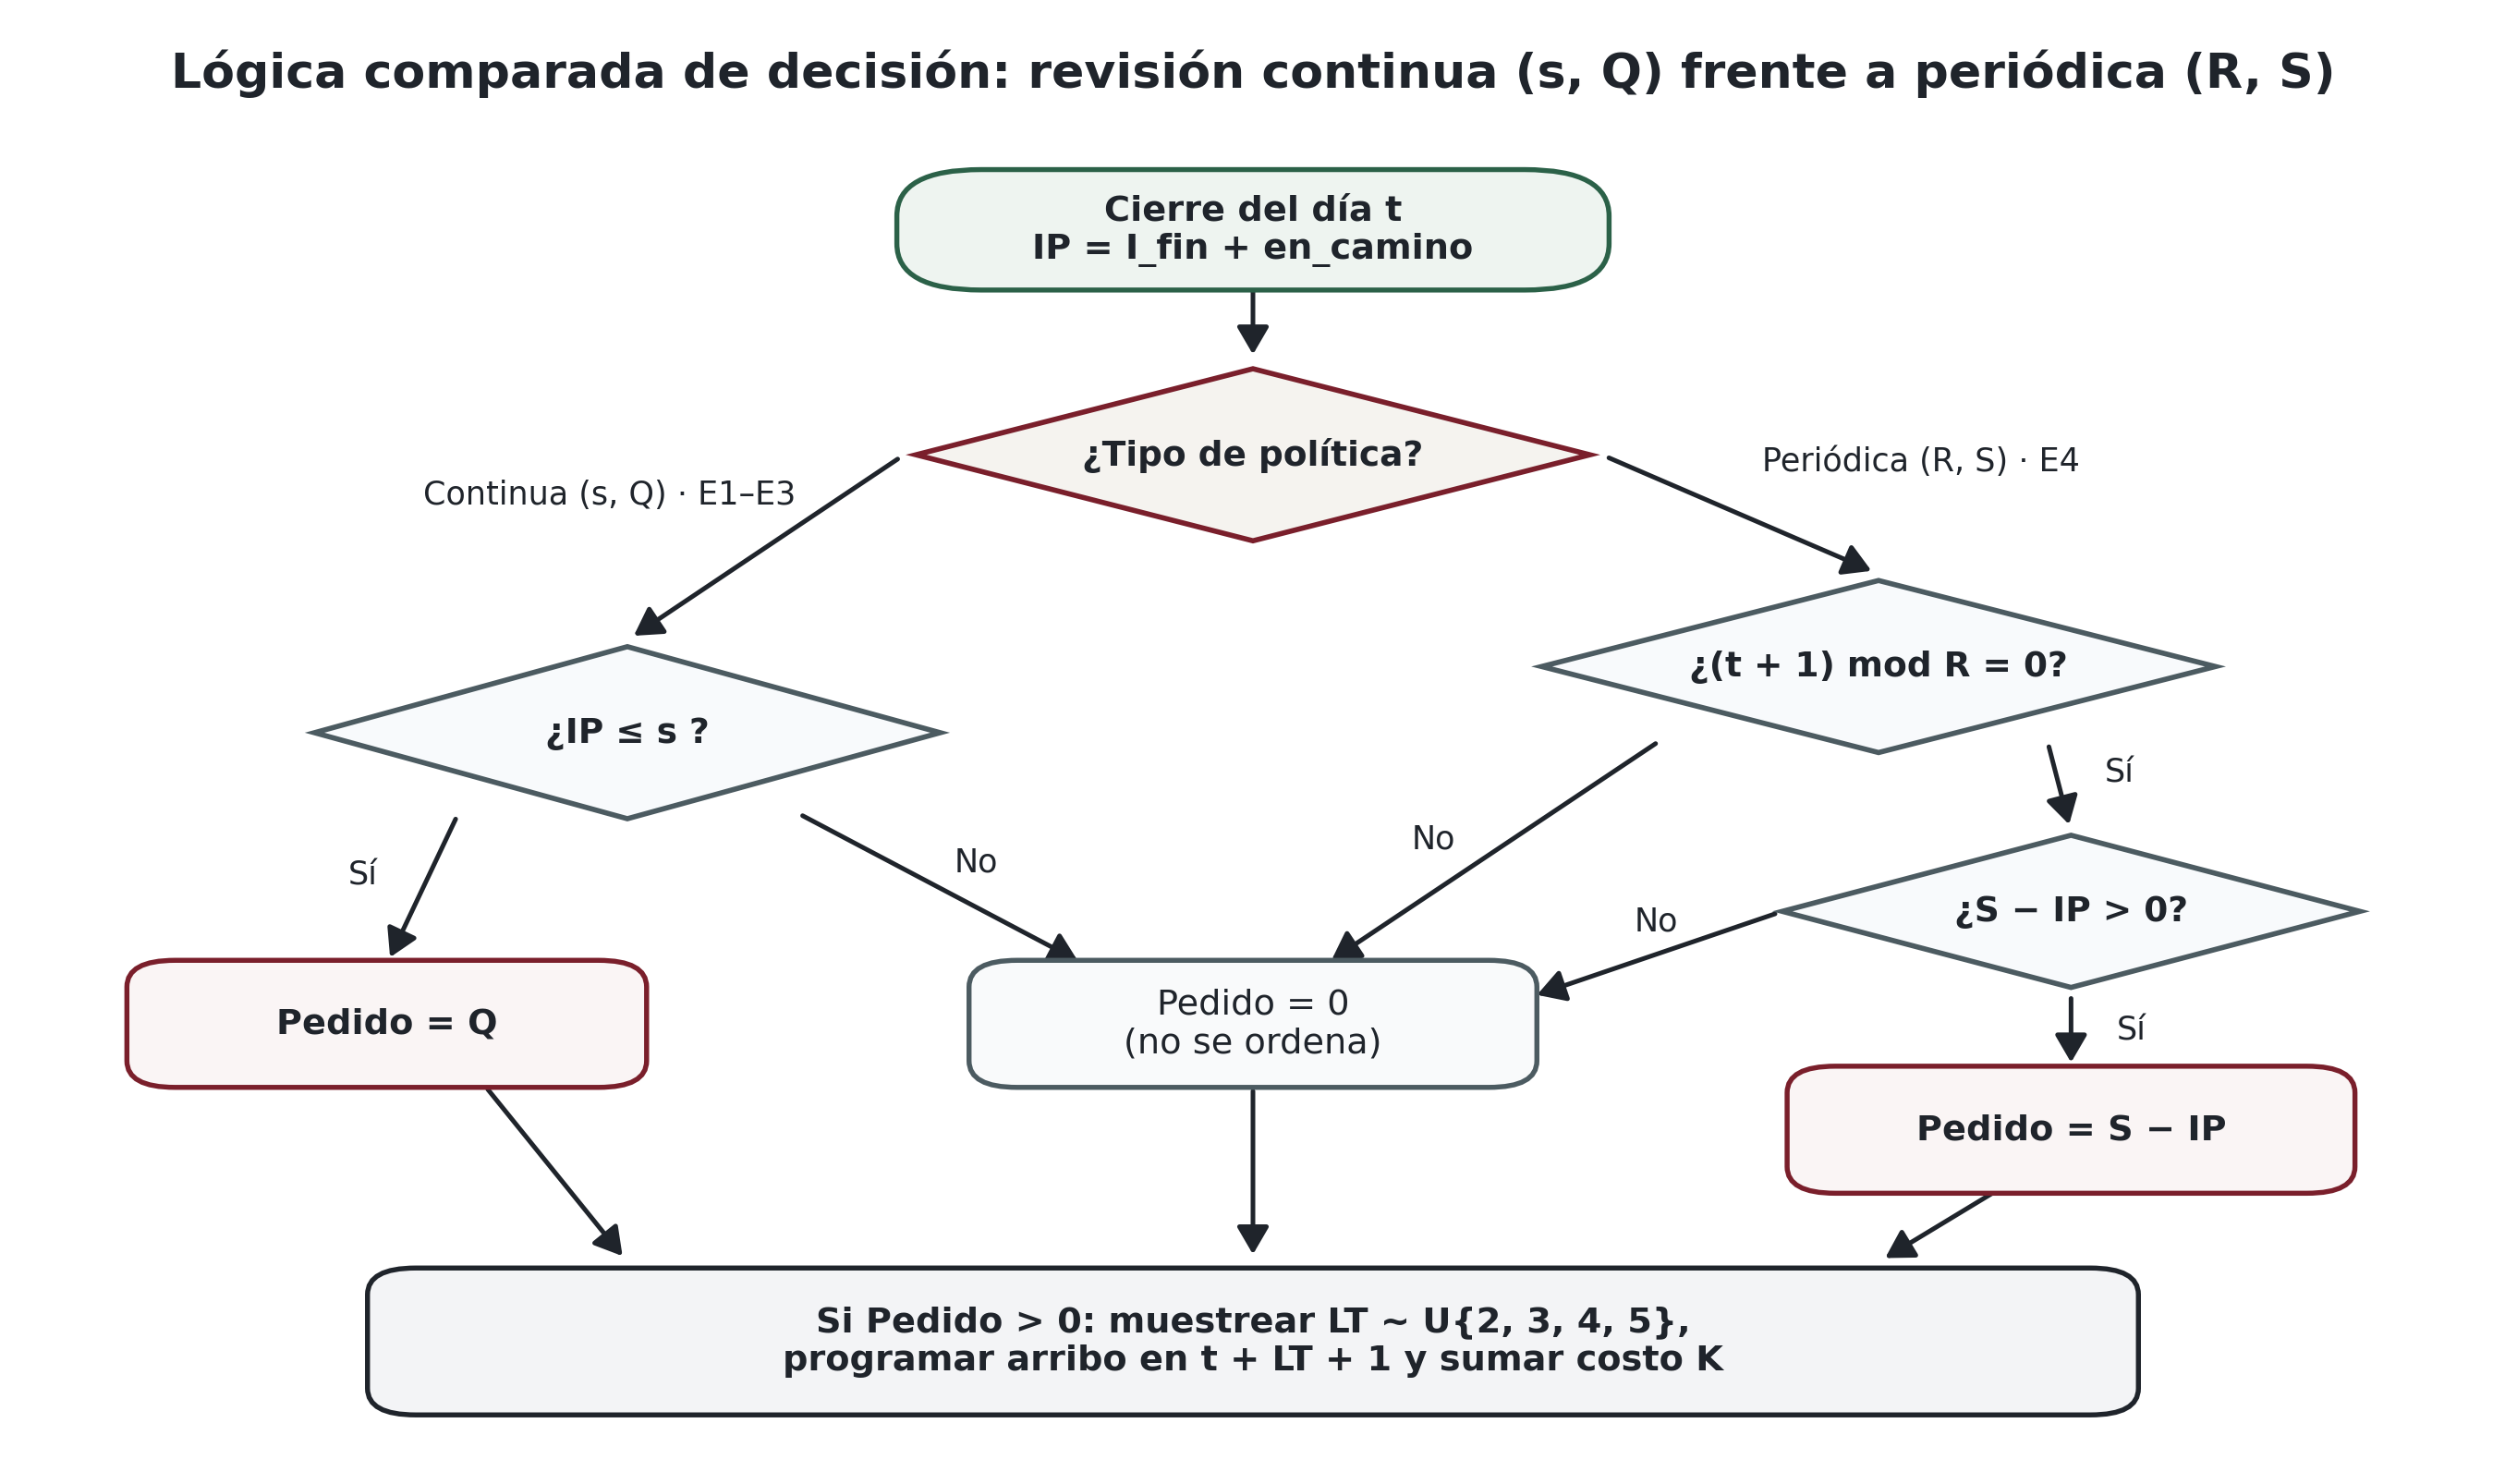

fig10_sensibilidad_penalizacion.png


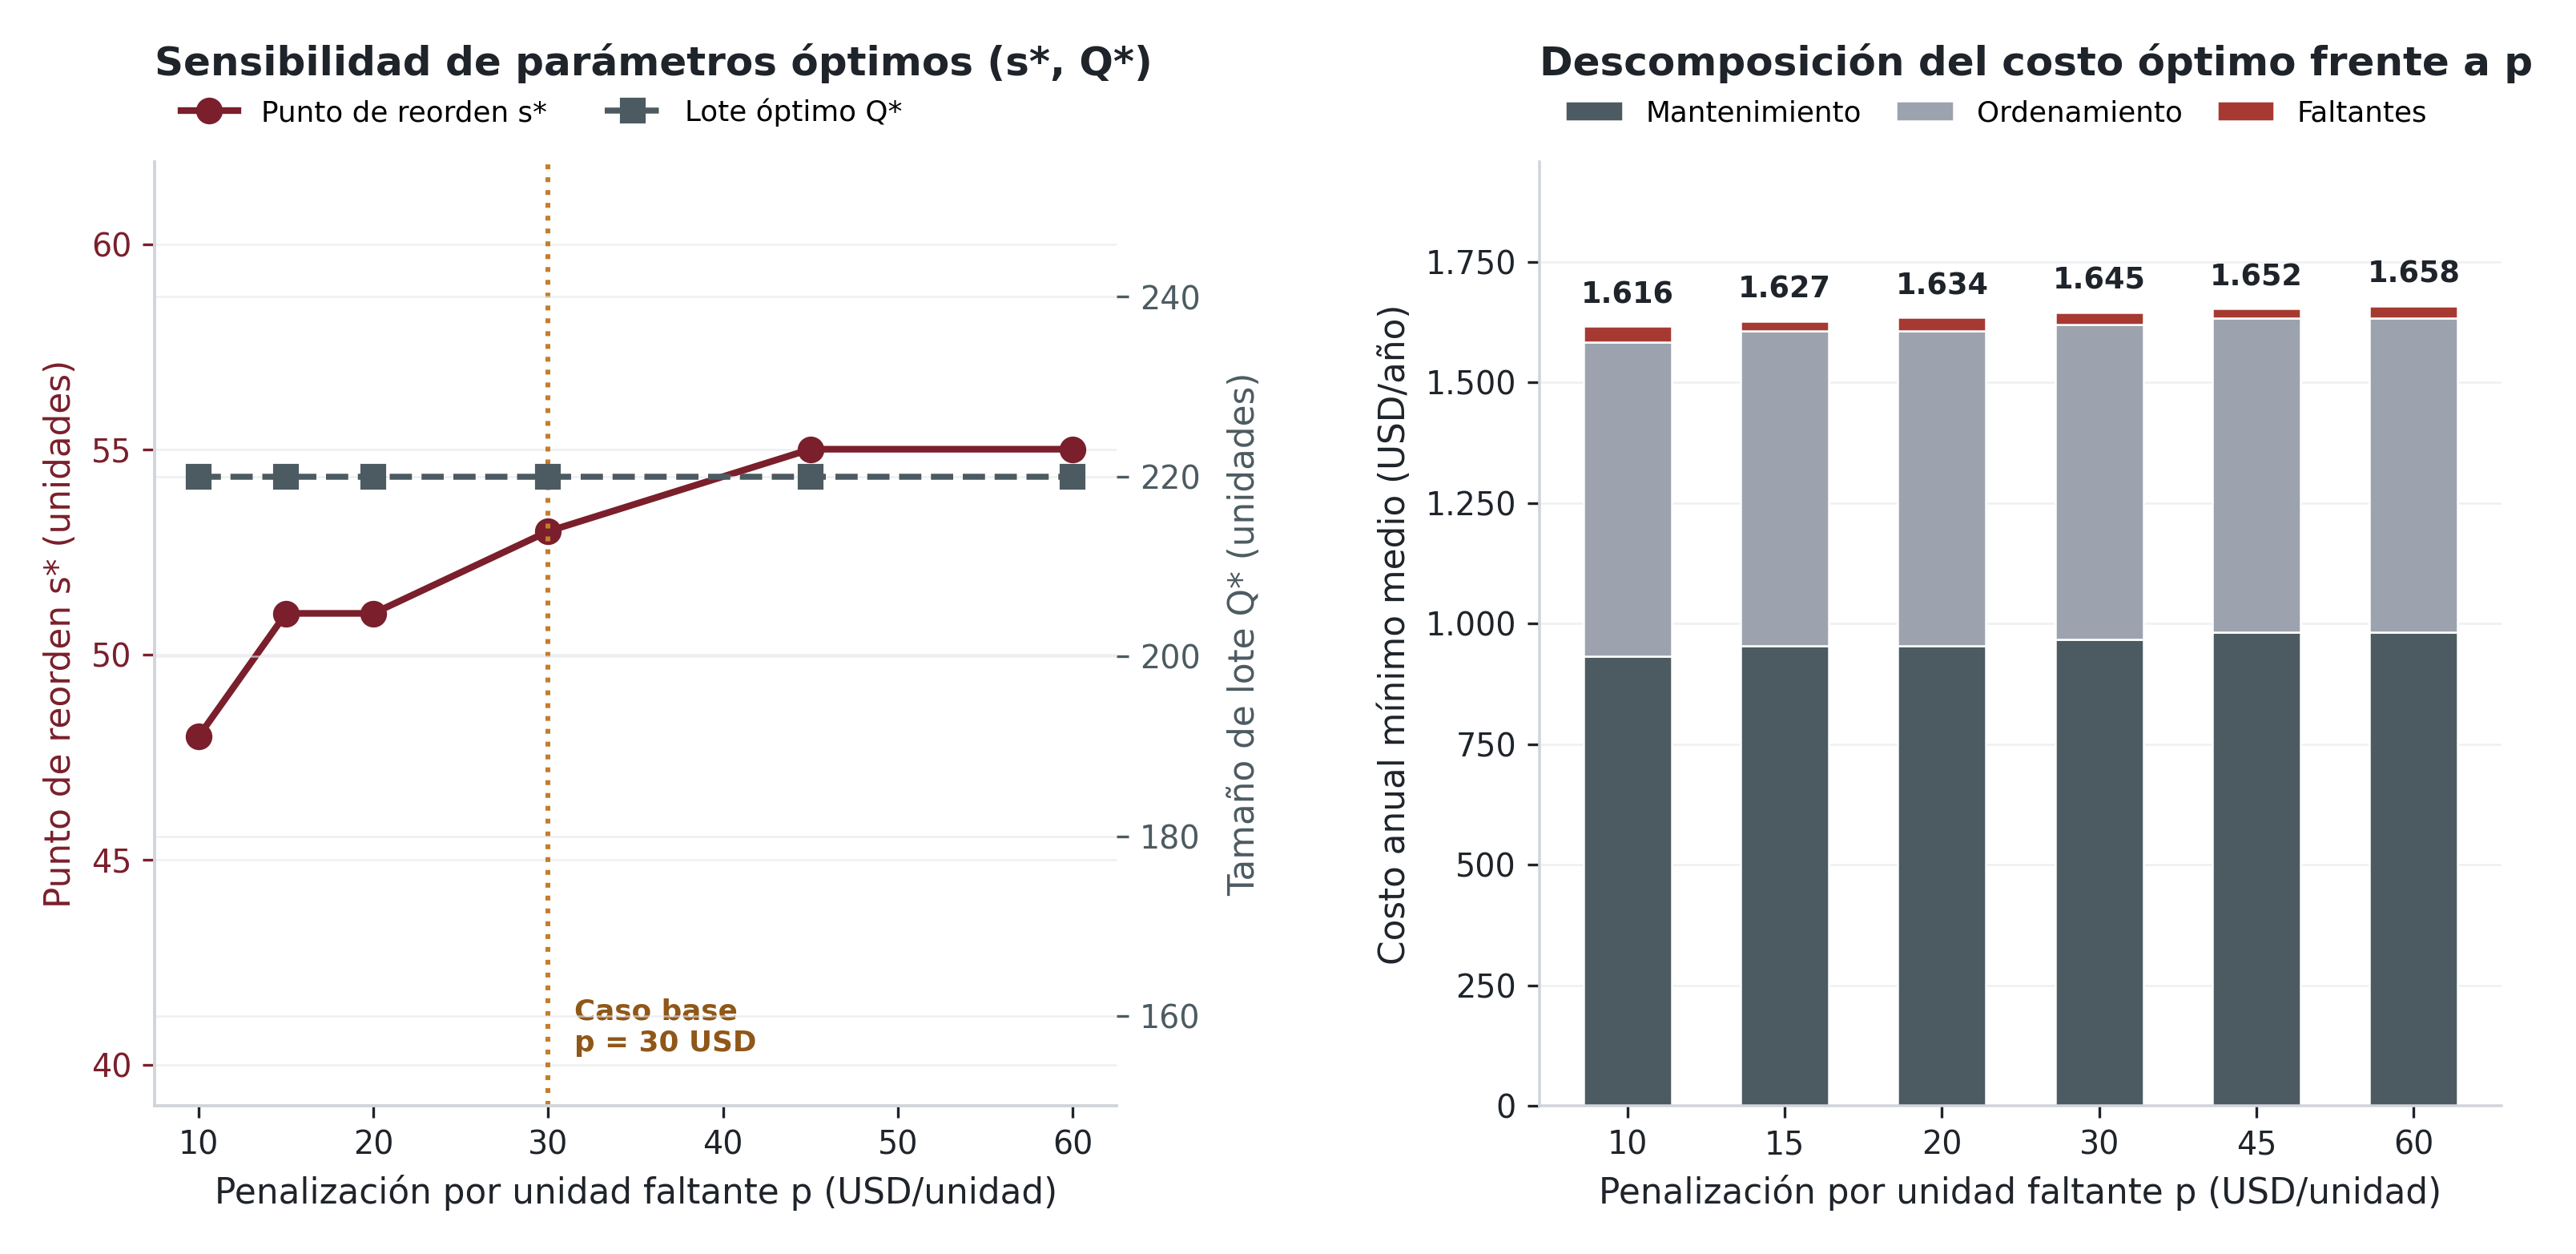

fig11_sensibilidad_K_LT.png


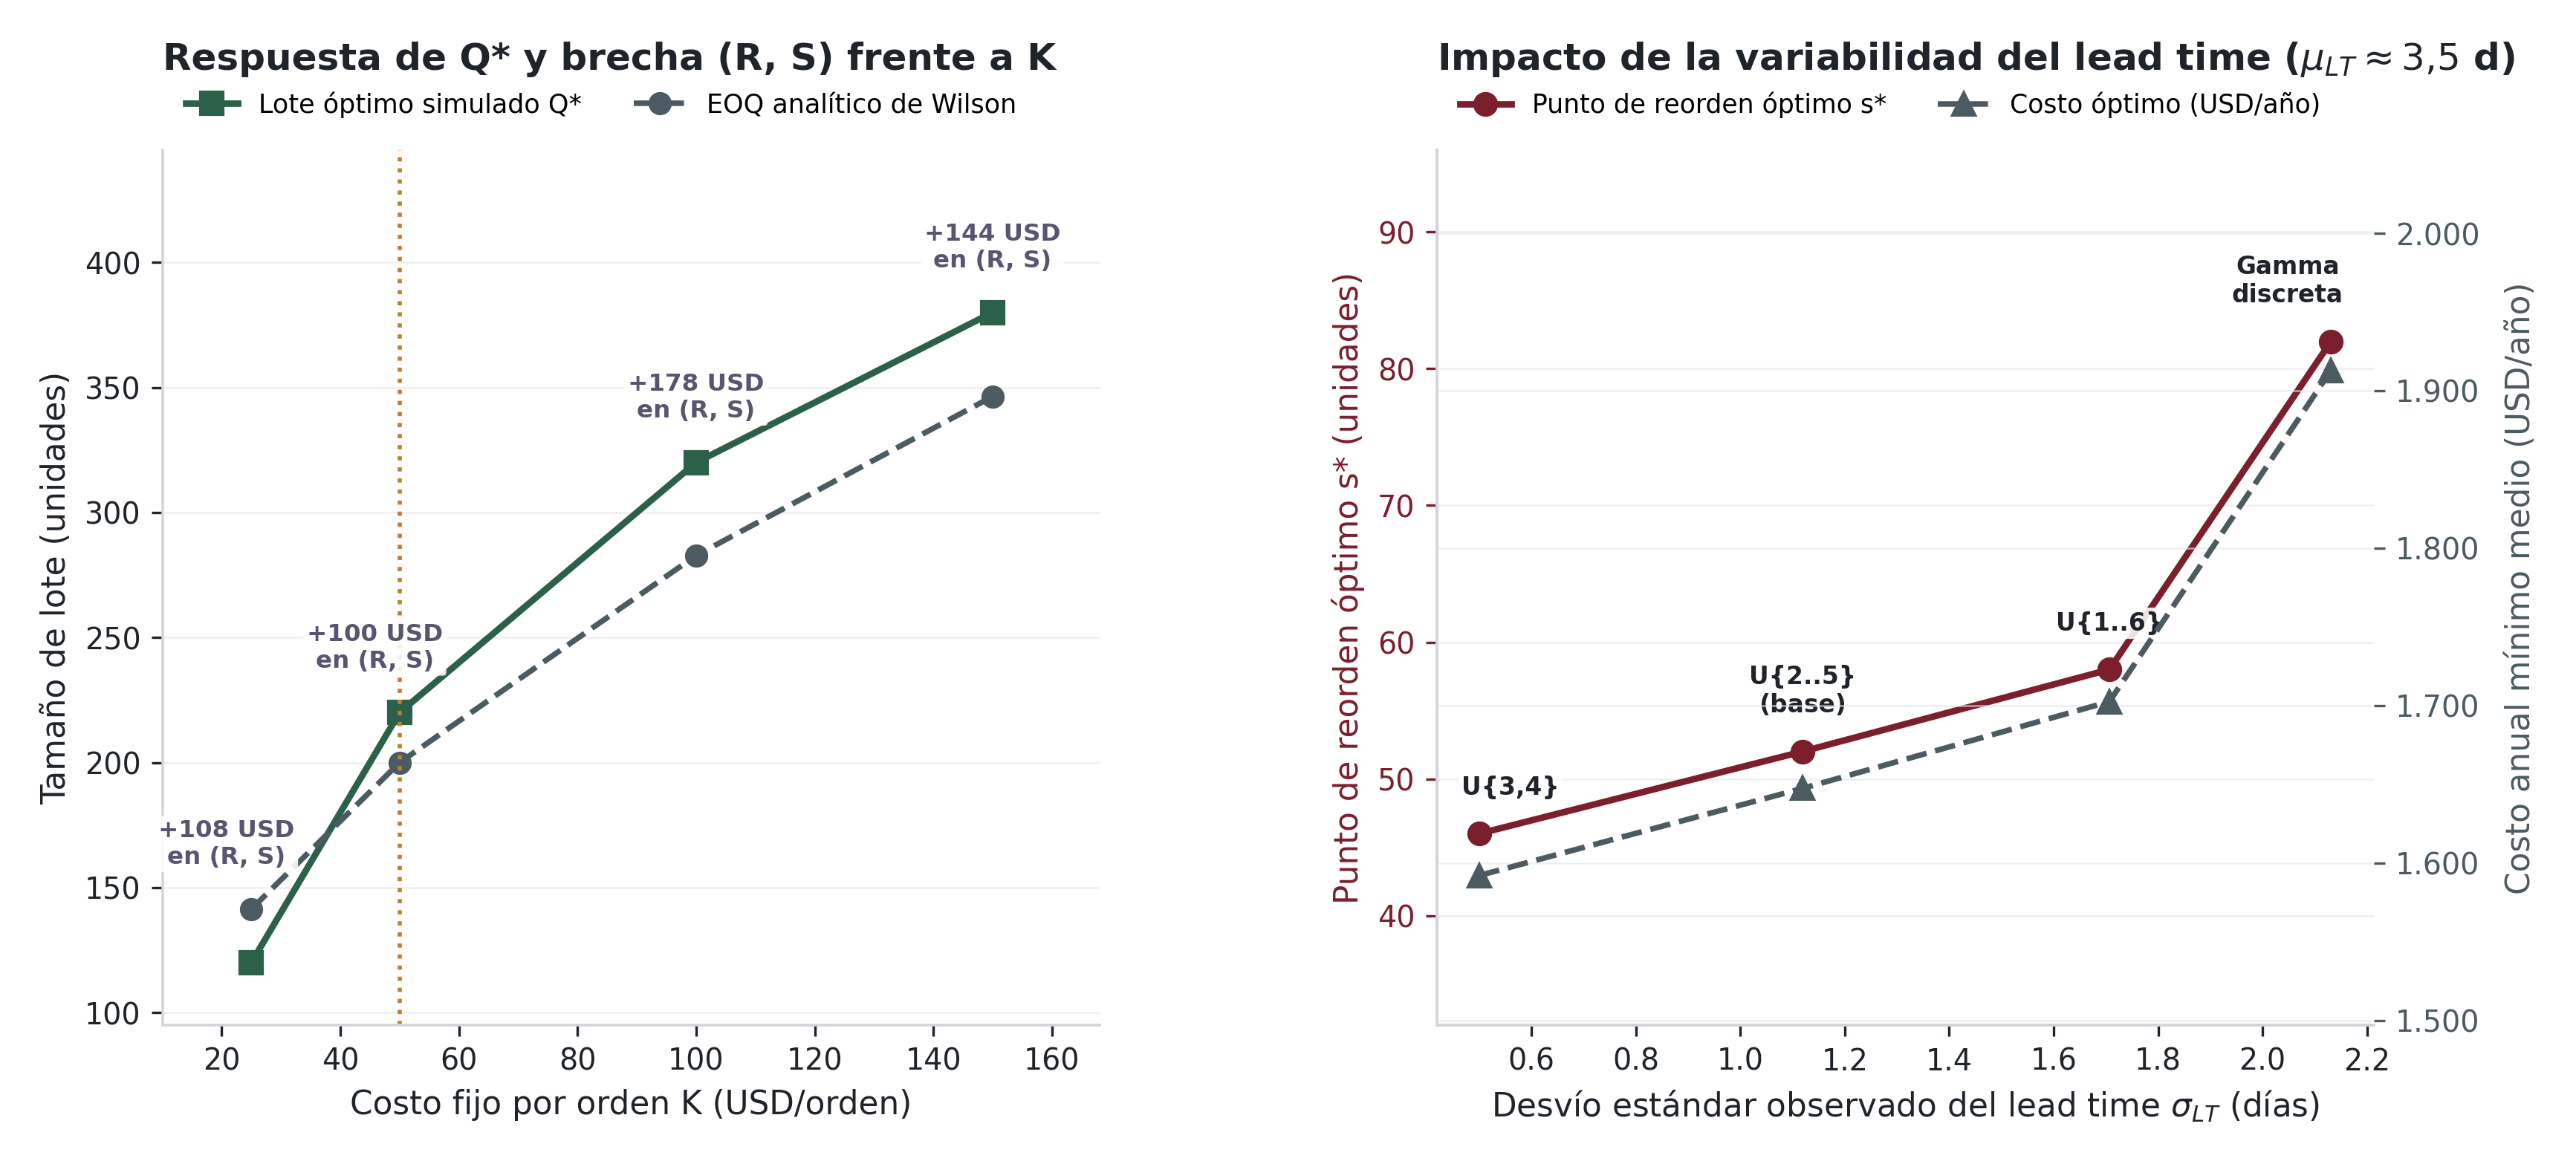

In [7]:
for nombre_fig in sorted(DIR_IMG.glob('fig*.png')):
    print(nombre_fig.name)
    display(Image(filename=str(nombre_fig), width=760))